# Predicting hydropower unit commitment in Tokke-Vinje: project report

**Name:** Martin Nordli Almenningen  
**Student id:** 562274  
**Kaggle team name:** [197] sur salamander  
**Group:** 197  
**Course:** TDT4173 Modern Machine Learning in Practice

The code cells produce the figures and computed tables from the raw data and the saved experiment results. Tables written by hand quote the experiment log. The notebook was run in my project directory and uses its helper modules, so it is a report to read, not a program to rerun. The two short notebooks are self-contained.

**How to read this report.** Section 1 tells the whole story on one page. Section 2 explains the task and the terms used throughout. Sections 3 to 11 give the evidence, Section 12 lists the limitations, and Section 13 sums up what I learned. The appendix explains the experiment numbers used in the text. Each section starts by saying which question it answers and why that question matters.

## Contents
1. Summary
2. The task and key terms
3. Exploratory data analysis
   - 3.1 Search domain knowledge
   - 3.2 Understand how the data was generated
   - 3.3 Check if the data is intuitive
   - 3.4 Explore individual features
   - 3.5 Explore pairs and groups of features
   - 3.6 Clean up features
4. Validation: how I measured progress
5. Feature engineering
6. All models and algorithms tried
7. Final models and hyperparameters
8. Model interpretation
9. Error analysis
10. Robustness
11. Reproducibility
12. Limitations
13. Conclusion

Appendix: experiment numbers

In [1]:
import sys, json, re, warnings
sys.path.insert(0, "src")
sys.dont_write_bytecode = True
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common import load_cases, years, auc, RES, INFLOW, MINFLOW, MINVOL
from lp_surrogate import UNITS
from features import TOPO, UP, DOWN, PMAX, PLANTS, group

BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2})
def heat(ax, M, xl, yl, title, vmin=None, vmax=None, fmt="{:.3f}", cmap="Blues", size=7):
    im = ax.imshow(M, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.grid(False)
    ax.set_xticks(range(len(xl)), xl)
    ax.set_yticks(range(len(yl)), yl)
    ax.set_title(title)
    lo, hi = np.nanmin(M) if vmin is None else vmin, np.nanmax(M) if vmax is None else vmax
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=size, color="white" if (M[i, j] - lo) / (hi - lo + 1e-12) > .6 else INK)
    return im

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
c = load_cases()
Y = c["Y"]
P = c["price"]
yr = years(c)
N_TR = 2922
ytr = yr[:N_TR]
YRS = list(range(2015, 2023))
starts = pd.to_datetime(c["start"])
rows = {}
for l in open("experiments.jsonl"):
    d = json.loads(l)
    rows[d["name"]] = d
# Final models: LP v5 (`lp5q`). The v4/v5 comparison was trained on CPU nodes for both LPs (Section 5.3).
XT, NT = np.load("artifacts/oof/XR5c_ls.npy").astype(np.float64), np.load("artifacts/oof/N6c_v5.npy").astype(np.float64)
B = .7 * XT + .3 * NT
Z = np.load("artifacts/lp/lp5q.npz")
LPF = Z["pfrac"].astype(np.float64)
LPU = Z["u"].astype(np.float64)
XF, NF = np.load("artifacts/fwd/XR5c_ls_f.npy").astype(np.float64), np.load("artifacts/fwd/N6fc_v5.npy").astype(np.float64)
B4 = .7 * np.load("artifacts/oof/XR_ls.npy").astype(np.float64) + .3 * np.load("artifacts/oof/N6_min.npy").astype(np.float64)  # final blend on LP v4, GPU
print("LOYO blend", round(auc(Y, B), 5), "| forward blend", round(auc(Y[np.isfinite(XF).all((1, 2))], (.7 * XF + .3 * NF)[np.isfinite(XF).all((1, 2))]), 5))

LOYO blend 0.9943 | forward blend 0.99404


## 1. Summary

**The problem.** Every day from 2015 to 2024, SINTEF's planning software SHOP decided when each of the 14 generating units in the Tokke-Vinje hydropower system should run during the coming week. The task is to predict those on/off decisions for 2023-2024 from the same inputs SHOP saw.

**The key observation.** The labels are not noisy measurements. They are the solution to an optimisation problem: earn as much as possible from selling power, while saving water that is worth more later. A model that only sees prices and reservoir data has to rediscover this logic from examples. That works up to a point: my best models built this way reached a cross-validated AUC of 0.986.

**The idea.** Instead of leaving the logic to the model, I rebuilt a simplified version of SHOP's optimisation problem as a linear program (LP), solved it for every case, and gave its plan to the models as input features. The LP has no trained parameters; the only thing it takes from the labels is the order in which identical units start. On its own, its plan already reaches an AUC of 0.97. The machine-learning models then only have to learn where SHOP deviates from the simplified plan.

**The result.** Adding the LP was by far the largest step in the project: the same LightGBM model went from 0.955 to 0.992. The final submission blends two different model types, XGBoost and a neural network (ST-Net), both built on the LP features. It reaches 0.9943 in cross-validation and 0.99651 on the public leaderboard. The final LP (version 5) includes two corrections found late in the project, which raised every model by about 0.0004 (Sections 5.1 and 5.3).

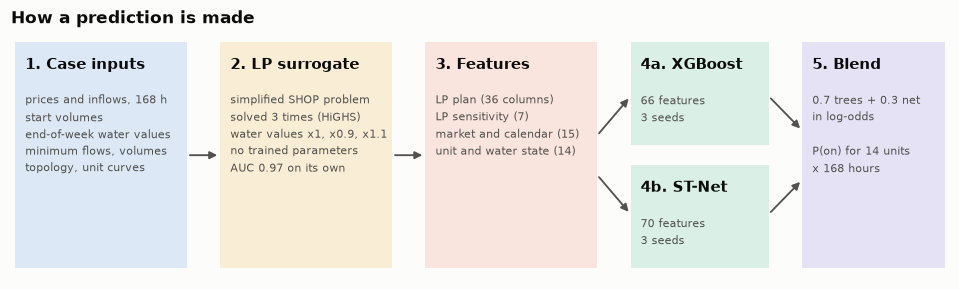

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.9))
ax.set_xlim(0, 11.2)
ax.set_ylim(.35, 2.85)
ax.axis("off")
def box(x, y, w, h, title, body, col):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=col, ec="none", alpha=.15))
    ax.text(x + .12, y + h - .16, title, fontsize=9.5, fontweight="bold", color=INK, va="top")
    ax.text(x + .12, y + h - .5, body, fontsize=7.4, color=MUTED, va="top", linespacing=1.5)
def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
box(.05, .45, 2.05, 2.3, "1. Case inputs", "prices and inflows, 168 h\nstart volumes\nend-of-week water values\nminimum flows, volumes\ntopology, unit curves", BLUE)
box(2.5, .45, 2.05, 2.3, "2. LP surrogate", "simplified SHOP problem\nsolved 3 times (HiGHS)\nwater values x1, x0.9, x1.1\nno trained parameters\nAUC 0.97 on its own", YELLOW)
box(4.95, .45, 2.05, 2.3, "3. Features", "LP plan (36 columns)\nLP sensitivity (7)\nmarket and calendar (15)\nunit and water state (14)", ORANGE)
box(7.4, 1.7, 1.65, 1.05, "4a. XGBoost", "66 features\n3 seeds", AQUA)
box(7.4, .45, 1.65, 1.05, "4b. ST-Net", "70 features\n3 seeds", AQUA)
box(9.45, .45, 1.7, 2.3, "5. Blend", "0.7 trees + 0.3 net\nin log-odds\n\nP(on) for 14 units\nx 168 hours", VIOLET)
arrow(2.1, 1.6, 2.5, 1.6)
arrow(4.55, 1.6, 4.95, 1.6)
arrow(7.0, 1.8, 7.4, 2.2)
arrow(7.0, 1.4, 7.4, 1.0)
arrow(9.05, 2.2, 9.45, 1.85)
arrow(9.05, 1.0, 9.45, 1.35)
ax.set_title("How a prediction is made")
plt.show()

| Submission | Model | Cross-validation, LOYO (2015-22) | Forward validation (2019-22) | Public leaderboard |
|---|---|---|---|---|
| **Short notebook 1** | XGBoost + ST-Net on LP v5, blend 0.7/0.3 | **0.99430** | **0.99404** | **0.99651** |
| **Short notebook 2** | Same, but ST-Net does not see absolute price levels | 0.99430 | 0.99408 | 0.99649 |
| Notebook 1 v4 | Same as notebook 1, on LP v4 | 0.99400 | 0.99379 | 0.99638 |
| Notebook 2 v4 | Same as notebook 2, on LP v4 | 0.99399 | 0.99379 | 0.99635 |
| Earlier blend (B2) | 3 tree models + 2 ST-Nets | 0.99377 | - | 0.99626 |
| Best without the LP (E021a) | LightGBM + ST-Net | 0.98584 | - | 0.98906 |

The two submissions differ in one choice only. In notebook 1 the neural network sees absolute price levels; in notebook 2 it does not. Their test predictions are almost identical (rank correlation 0.99913). Notebook 2 is a hedge in case the price levels of 2023-24 mislead the network (Section 10.2). I chose models by cross-validation, not by the public leaderboard, since grading uses the private leaderboard.

The most important limitation (Section 12): I chose the LP's design by checking it against labels from all training years, including the two corrections in LP v5, so no year is fully untouched, and the validation scores are probably slightly optimistic.

## 2. The task and key terms

SHOP planned one week (168 hours) at a time for Tokke-Vinje, a hydropower system with 17 reservoirs, 9 power plants and 14 generating units, about 1000 MW in total. A new plan was made every day from 2015-01-01 to 2024-12-25, and each plan is one *case*. For each case the task is to predict, for every unit and hour, whether the unit runs. Predictions are probabilities, scored with ROC AUC over all unit-hours together (micro-averaged). AUC only measures ranking: 1.0 means every running unit-hour is ranked above every idle one, and 0.5 is guessing.

- **Training data:** 2922 cases from 2015-2022, with labels.
- **Test data:** 725 cases from 2023-01-01 to 2024-12-25, without labels. The test period comes after all training data, so the models must work in years they have never seen.
- **Inputs per case:** hourly electricity prices and inflows, reservoir volumes at the start, water values at the end of the week, minimum flow and volume rules, and the system's topology (which reservoir drains through which plant into which reservoir).

Since grading is determined by the private leaderboard score, which I cannot see, I optimised for performance in new years, not for the public score.

**Key terms used in the report**

| Term | Meaning |
|---|---|
| SHOP | SINTEF's hydropower scheduling software. It produced the labels. |
| Water value | What a reservoir's water is expected to be worth in the future, in EUR/MWh. Running a unit uses water, so it only pays when the price is above this value. |
| Cascade | Reservoirs and plants in series: water released through one plant flows into the next reservoir down. |
| LP | Linear program. Here: my simplified, fast-to-solve version of SHOP's planning problem (Section 5.1). |
| LOYO | Leave-one-year-out cross-validation: train on seven of the years 2015-2022, predict the eighth, and repeat for all eight. |
| Forward validation | Train only on years before the validation year (2019, 2020, 2021 or 2022). Closest to the real situation. |
| Gate | My fixed rule for accepting a change (Section 4). |
| Seed noise | How much a score moves when only the random seed changes. Differences smaller than this are not trusted. |
| Absolute price columns | Columns holding a price or water value level itself, such as 80 EUR/MWh, as opposed to relative columns such as price compared with the week's median. |
| ST-Net | My neural network. It treats every (unit, hour) as a token and lets units exchange information (Section 7). |
| Blend in log-odds | The final prediction averages the two models' log-odds, not their probabilities. |
| Nested | Weights chosen inside each fold, so the validation year is never used to choose them. |
| `lp_*`, `ls_*` | Feature columns from the LP's plan, and from the LP solved again with changed water values (Section 5.2). |
| E..., L..., N..., X..., R... | IDs of runs in my experiment log. The tables in Section 6 say what each E, L, N and X run tested, and the appendix explains each R number and links to the full log. |

## 3. Exploratory data analysis

The main goal of the exploration was to understand what drives SHOP's decisions well enough to know what features could capture it. The six subsections follow the course's list of EDA items.

### 3.1 Search domain knowledge

Before looking at the data I read the task description, the dataset documentation, the SHOP documentation and the topology files. Six facts shaped the rest of the work:

- **Water value decides.** A unit should roughly run when the electricity price is above the value of the water it uses. The price alone is therefore not enough; it has to be compared with the water value.
- **Water is used again further down.** Water released from an upper plant ends up in a lower reservoir, where it can produce power again. The real cost of running a plant therefore depends on where its water goes, not only on its own reservoir.
- **Efficiency depends on flow and head.** Power is not proportional to water flow. It grows more slowly at high flow (it is concave), and it depends on the height the water falls (head) and on losses in tunnels and pipes.
- **On/off decisions make the problem hard.** Start costs and minimum power output mean a unit is either off or running above some level. This makes SHOP's problem a mixed-integer program, which is much harder to solve than a linear one. Where several units are identical, the solver needs a fixed order to decide which one starts first.
- **Environmental rules can force production.** Minimum flows and minimum reservoir volumes can force water through a plant, or past it, whatever the price.
- **Floods make water nearly free.** Water that would otherwise spill over a dam has almost no value, so units may run even at very low prices.

### 3.2 Understand how the data was generated

The labels are the output of an optimiser (SHOP v17.17.0) run on a fixed model of the system, not noisy measurements. This has two consequences that guided the whole project:

1. If SHOP's decisions follow from its inputs, an error a model makes is something it has not yet understood about the problem, not random noise. This is why I later rebuilt the optimisation problem itself (Section 5.1).
2. Only what SHOP received when it made the plan is a legitimate input: 168 hours of prices, inflows and rules, reservoir volumes at the start day, and water values at the end of the week. Later volumes or water values would leak information from the future, so my feature code cannot reach them.

A new case starts every day and covers seven days, so neighbouring cases overlap in six of their seven days. The cell below checks how stable SHOP's plan is when the same hours are planned again a day later, and whether identical units start in a fixed order.

In [3]:
agree = {f"{l} day(s) later": float((Y[l:, :, :168 - 24 * l] == Y[:-l, :, 24 * l:]).mean()) for l in (1, 2, 3, 6)}
uc = pd.read_csv("data/kernel/Unit_commitment_decisions.csv", usecols=["starttime", "total_calculation_time"], parse_dates=["starttime"])
print("Share of identical decisions for the same clock hour when solved again:", {k: round(v, 3) for k, v in agree.items()})
print("SHOP solve time per case, seconds:", uc.total_calculation_time.describe()[["min", "50%", "max"]].round(1).to_dict())
print("Median per year:", uc.groupby(uc.starttime.dt.year).total_calculation_time.median().round(1).to_dict())
print("Label shape", Y.shape, "| share on", round(Y.mean(), 4), "| unit-weeks with constant on/off:", round(((Y.sum(2) == 0) | (Y.sum(2) == 168)).mean(), 3))
i = UNITS.index
print("\nFixed order among identical units, share of hours where the first is on whenever the second is:")
for a, b in [("Vinje_G1", "Vinje_G2"), ("Vinje_G2", "Vinje_G3"), ("Tokke_G1", "Tokke_G3"), ("Tokke_G3", "Tokke_G2"), ("Tokke_G3", "Tokke_G4"), ("Tokke_G4", "Tokke_G2")]:
    print(f"  {a} >= {b}: {(Y[:, i(a)] >= Y[:, i(b)]).mean():.4f}")

Share of identical decisions for the same clock hour when solved again: {'1 day(s) later': 0.878, '2 day(s) later': 0.812, '3 day(s) later': 0.779, '6 day(s) later': 0.742}
SHOP solve time per case, seconds: {'min': 22.4, '50%': 51.7, 'max': 4525.7}
Median per year: {2015: 50.5, 2016: 53.1, 2017: 61.6, 2018: 60.3, 2019: 60.5, 2020: 51.8, 2021: 45.3, 2022: 38.2}
Label shape (2922, 14, 168) | share on 0.5164 | unit-weeks with constant on/off: 0.588

Fixed order among identical units, share of hours where the first is on whenever the second is:
  Vinje_G1 >= Vinje_G2: 0.9993
  Vinje_G2 >= Vinje_G3: 0.9998
  Tokke_G1 >= Tokke_G3: 0.9995
  Tokke_G3 >= Tokke_G2: 0.9994
  Tokke_G3 >= Tokke_G4: 0.9971
  Tokke_G4 >= Tokke_G2: 0.9813


- **Plans change when they are made again.** For the same clock hour, only 88 % of decisions are the same in the plan made one day later, and 74 % in the plan made six days later. New information about prices and inflow changes the plan, so each case has to be predicted on its own terms. Averaging predictions across overlapping cases made every year worse (Section 6.1).
- **Many unit-weeks are constant.** In 59 % of unit-weeks a unit is either on all week or off all week. Getting the weekly level right is therefore as important as getting the hour-by-hour timing right.
- **Identical units start in a fixed order.** For example, Vinje G2 almost never runs without Vinje G1 (99.93 % of hours). This is how SHOP breaks the tie between identical units (Section 3.1). The LP uses all six orderings above. The neural network enforces the first five, since the last holds in only 98.1 % of hours.

### 3.3 Check if the data is intuitive

Based on my findings from 3.1, two things should hold: units should run when the price is above the water value, and the share of units running should follow the market. The figures below test both.

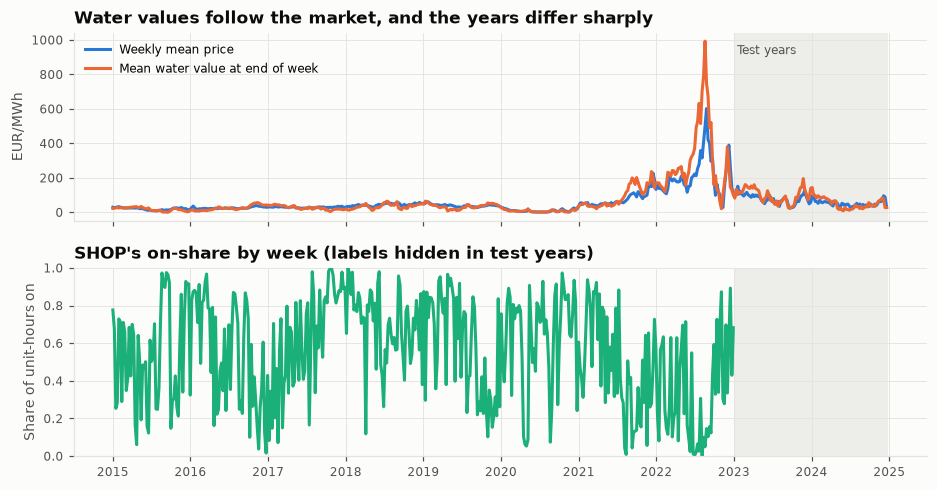

In [4]:
ri = {r: k for k, r in enumerate(RES)}
wk = np.arange(0, len(P), 7)
dates = starts[wk]
wv = c["wv_end"]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw=dict(hspace=.25))
ax[0].plot(dates, P.mean(1)[wk], color=BLUE, label="Weekly mean price")
ax[0].plot(dates, wv.mean(1)[wk], color=ORANGE, label="Mean water value at end of week")
ax[0].axvspan(starts[N_TR], starts[-1], color=GRID, alpha=.6, lw=0)
ax[0].text(starts[N_TR + 15], ax[0].get_ylim()[1] * .88, "Test years", fontsize=8, color=MUTED)
ax[0].set_ylabel("EUR/MWh")
ax[0].set_title("Water values follow the market, and the years differ sharply")
ax[0].legend(loc="upper left")
ax[1].plot(starts[:N_TR][wk[wk < N_TR]], Y[wk[wk < N_TR]].mean((1, 2)), color=AQUA)
ax[1].axvspan(starts[N_TR], starts[-1], color=GRID, alpha=.6, lw=0)
ax[1].set_ylabel("Share of unit-hours on")
ax[1].set_title("SHOP's on-share by week (labels hidden in test years)")
ax[1].set_ylim(0, 1)
plt.show()

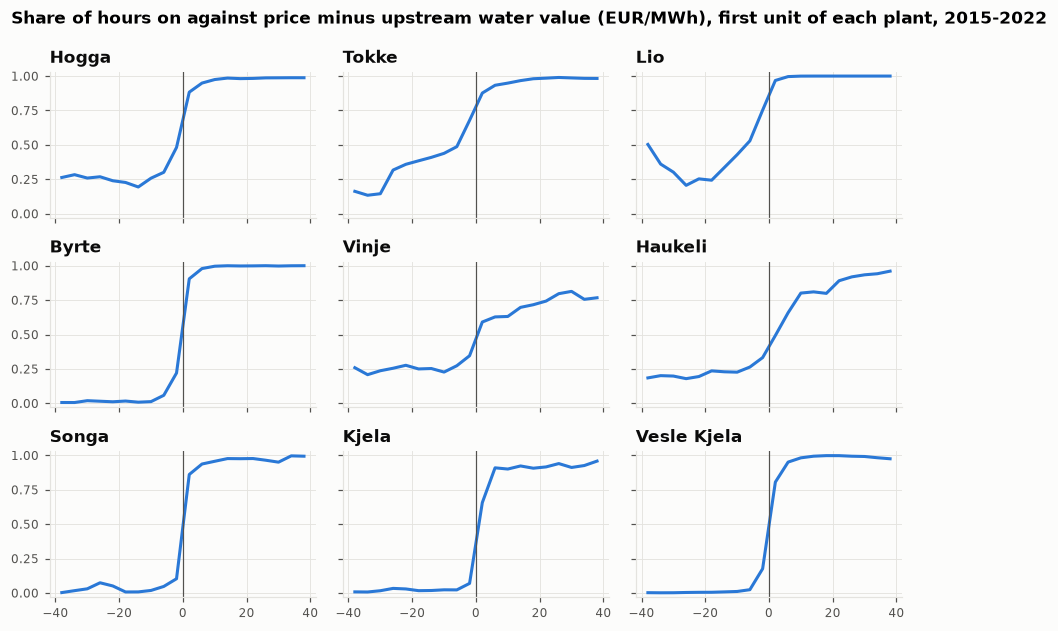

,plant,weeks,coef_wv_up,coef_wv_down,intercept,R2
0,Hogga,1080,0.86,0.00,-2.82,0.87
1,Tokke,1141,0.58,0.26,0.39,0.81
2,Lio,671,0.49,0.12,11.13,0.92
3,Byrte,584,1.04,-0.03,-0.32,0.98
4,Vinje,1074,0.53,0.50,5.90,0.92
5,Haukeli,454,0.57,0.13,17.37,0.79
6,Songa,792,0.72,0.12,8.11,0.94
7,Kjela,905,0.71,0.15,10.98,0.96
8,Vesle Kjela,575,0.86,0.07,3.97,0.95


In [5]:
fig, axs = plt.subplots(3, 3, figsize=(10, 6.2), sharex=True, sharey=True, gridspec_kw=dict(hspace=.3, wspace=.1))
bins = np.arange(-40, 41, 4)
rowsT = []
for ax, pl in zip(axs.ravel(), PLANTS):
    u0 = [k for k, u in enumerate(UNITS) if TOPO.gen_plant[u] == pl][0]
    w = wv[:N_TR, ri[UP[u0]]]
    d = (P[:N_TR] - w[:, None]).ravel()
    y = Y[:, u0].ravel()
    b = np.digitize(d, bins)
    xs, ys = [], []
    for k in range(1, len(bins)):
        if (b == k).sum() > 200:
            xs.append((bins[k - 1] + bins[k]) / 2)
            ys.append(y[b == k].mean())
    ax.plot(xs, ys, color=BLUE)
    ax.axvline(0, color=MUTED, lw=.8)
    ax.set_title(pl)
    ax.set_ylim(-.03, 1.03)
    on = Y[:, u0].astype(bool)
    mix = (on.sum(1) >= 12) & (on.sum(1) <= 156)
    th = np.array([(np.median(P[k][on[k]]) + np.median(P[k][~on[k]])) / 2 for k in np.where(mix)[0]])
    wu = wv[:N_TR, ri[UP[u0]]][mix]
    wd = wv[:N_TR, ri[DOWN[u0]]][mix] if DOWN[u0] else np.zeros(mix.sum())
    A = np.c_[wu, wd, np.ones(len(wu))]
    co = np.linalg.lstsq(A, th, rcond=None)[0]
    rowsT.append(dict(plant=pl, weeks=int(mix.sum()), coef_wv_up=co[0], coef_wv_down=co[1], intercept=co[2], R2=1 - ((th - A @ co) ** 2).sum() / ((th - th.mean()) ** 2).sum()))
fig.suptitle("Share of hours on against price minus upstream water value (EUR/MWh), first unit of each plant, 2015-2022", fontsize=11, fontweight="bold", x=.09, ha="left", y=.97)
plt.show()
display(pd.DataFrame(rowsT).round(2))

It holds true for the most part, but there are a few clear exceptions:

- **Price and water value move together.** Weekly mean price and mean water value correlate at 0.93 (top figure). A high price therefore does not by itself mean that a unit should run, because the water is then also worth more. This is why my features compare price with water value instead of using the price alone.
- **The margin "price minus water value" works.** In the 3x3 figure, the share of hours on rises sharply where the price passes the water value (margin 0). Byrte, Songa, Kjela and Vesle Kjela are close to clean on/off steps. Hogga, Tokke, Lio, Vinje and Haukeli still run 15-50 % of the time at strongly negative margins, probably because of minimum flow rules or water that would otherwise spill.
- **The table** estimates a rough price threshold for each week (midway between the median price when the unit is on and when it is off) and regresses it on the water values above and below the plant. The water value above gets the largest weight for every plant, but Vinje and Tokke also give weight to the one below. The estimate is crude, so I treated it only as a hint.

How to convert water values into money turned out to be less obvious than this suggests, and it mattered a great deal for the LP (Section 5.1).

### 3.4 Explore individual features

Next, each input on its own: price levels per year, how often each unit runs, the seasons, and the price distribution in training against test years.

,min,median,mean,max,% negative hours
"Price, EUR/MWh",,,,,
2015,1.03,21.96,19.82,69.68,0.00
2016,6.01,23.60,25.15,95.06,0.00
2017,2.97,28.94,28.83,114.70,0.00
2018,1.92,43.63,43.25,105.02,0.00
2019,5.86,38.81,39.26,109.45,0.00
2020,-1.73,6.95,9.29,99.92,0.06
2021,-1.97,59.34,75.11,600.16,0.06
2022,0.04,181.13,211.28,844.00,0.00
2023,-61.84,80.46,79.44,261.85,1.99


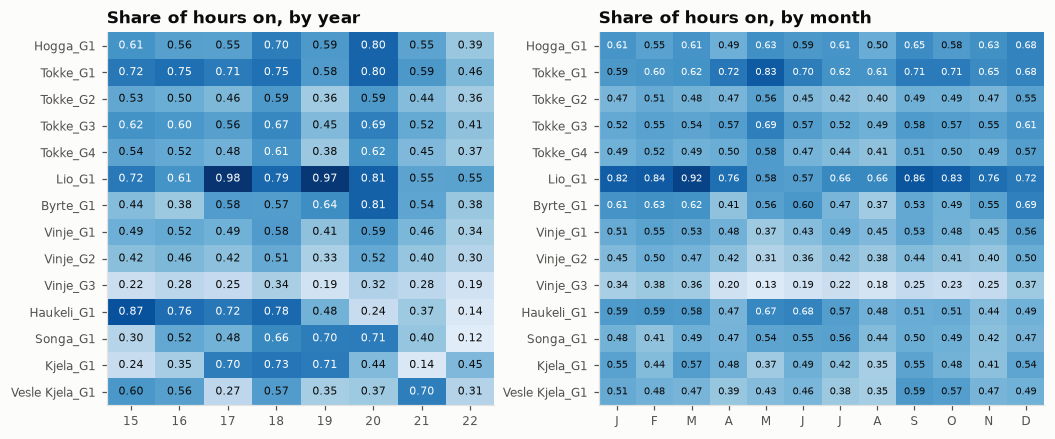

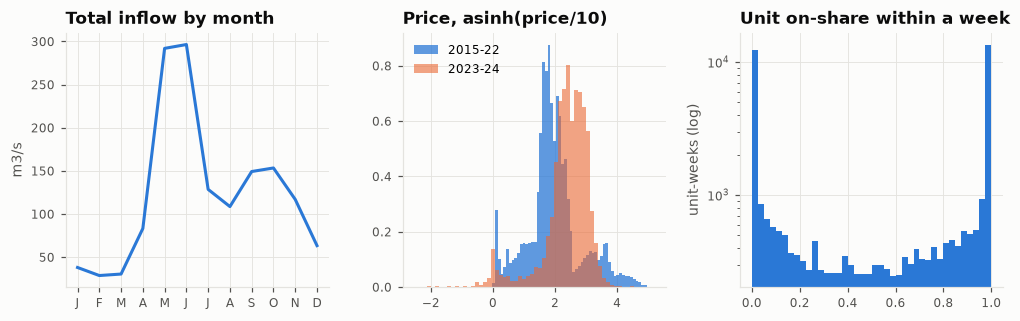

Hours with negative prices inside cases, train: 0.014 % | test: 2.18 %
Switches per unit-week: {'Hogga_G1': 1.7, 'Tokke_G1': 3.0, 'Tokke_G2': 2.0, 'Tokke_G3': 2.5, 'Tokke_G4': 2.1, 'Lio_G1': 1.2, 'Byrte_G1': 1.0, 'Vinje_G1': 3.0, 'Vinje_G2': 3.3, 'Vinje_G3': 3.6, 'Haukeli_G1': 0.5, 'Songa_G1': 2.0, 'Kjela_G1': 2.3, 'Vesle Kjela_G1': 0.7}


In [6]:
h = pd.read_csv("data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"]).set_index("date").iloc[:, 0]
h.index = pd.to_datetime(h.index, utc=True)
h = h["2015":"2024-12-31"]
g = h.groupby(h.index.year)
display(pd.DataFrame({"min": g.min(), "median": g.median(), "mean": g.mean(), "max": g.max(), "% negative hours": g.apply(lambda s: (s < 0).mean() * 100)}).round(2).rename_axis("Price, EUR/MWh"))
months = starts[:N_TR].month.values
ml = "J F M A M J J A S O N D".split()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw=dict(wspace=.25, width_ratios=[1, 1.15]))
heat(ax[0], np.array([[Y[ytr == y, g_].mean() for y in YRS] for g_ in range(14)]), [str(y)[2:] for y in YRS], UNITS, "Share of hours on, by year", 0, 1, "{:.2f}")
heat(ax[1], np.array([[Y[months == m, g_].mean() for m in range(1, 13)] for g_ in range(14)]), ml, UNITS, "Share of hours on, by month", 0, 1, "{:.2f}", size=6.5)
plt.show()
hh = (P[:N_TR] - np.median(P[:N_TR], 1, keepdims=True))
q = pd.read_csv("data/kernel/Historical_inflow_1958_2025.csv", parse_dates=["date"]).set_index("date")
q.index = pd.to_datetime(q.index, utc=True)
q15 = q["2015":"2022"]
fig, ax = plt.subplots(1, 3, figsize=(11, 3), gridspec_kw=dict(wspace=.28))
ax[0].plot(range(1, 13), q15.sum(axis=1).groupby(q15.index.month).mean(), color=BLUE)
ax[0].set_xticks(range(1, 13), ml)
ax[0].set_title("Total inflow by month")
ax[0].set_ylabel("m3/s")
ax[1].hist(np.arcsinh(h.loc["2015":"2022"] / 10), bins=60, color=BLUE, density=True, label="2015-22", alpha=.75)
ax[1].hist(np.arcsinh(h.loc["2023":] / 10), bins=60, color=ORANGE, density=True, label="2023-24", alpha=.6)
ax[1].set_title("Price, asinh(price/10)")
ax[1].legend()
ll = Y.mean(2).ravel()
ax[2].hist(ll, bins=40, color=BLUE)
ax[2].set_title("Unit on-share within a week")
ax[2].set_yscale("log")
ax[2].set_ylabel("unit-weeks (log)")
plt.show()
print("Hours with negative prices inside cases, train:", round(float((P[:N_TR] < 0).mean()) * 100, 3), "% | test:", round(float((P[N_TR:] < 0).mean()) * 100, 2), "%")
print("Switches per unit-week:", {u: round(float(v), 1) for u, v in zip(UNITS, np.abs(np.diff(Y, axis=2)).sum(2).mean(0))})

- **The years are very different.** The median price ranged from 7 EUR/MWh in 2020 to 181 in 2022, yet the share of hours on was higher in 2020 (0.60) than in 2022 (0.34). Price level alone does not explain the labels; the water values have to be taken into account.
- **Prices have extreme values.** Prices reach 898 and -62 EUR/MWh. I use `asinh(price/10)`, which behaves like a logarithm for large values but also handles negative ones.
- **The test years contain something new: negative prices.** They make up 2.2 % of test hours but only 0.014 % of training hours. Otherwise test prices stay within the training range (maximum 898 against 844). A model cannot learn from situations it has never seen, so this became the main risk for the test period (Sections 10.2 and 12).
- **Seasons.** Inflow peaks in May and June, with a smaller peak in autumn. Units react differently: Tokke G1 runs most in May (83 % of hours), while Lio and Vinje G3 run less then.
- **Units differ.** Vinje G3 runs in 26 % of hours and Lio in 75 %. The same unit also changes between years: Kjela ran in 14 % of hours in 2021 and in 73 % in 2018. A model needs to know which unit it predicts for.
- **Weekly on-share is bimodal**, with spikes at 0 and 1, which matches the constant unit-weeks in Section 3.2.

### 3.5 Explore pairs and groups of features

Here I look at how units and inputs relate to each other, and whether the test years look like the training years.

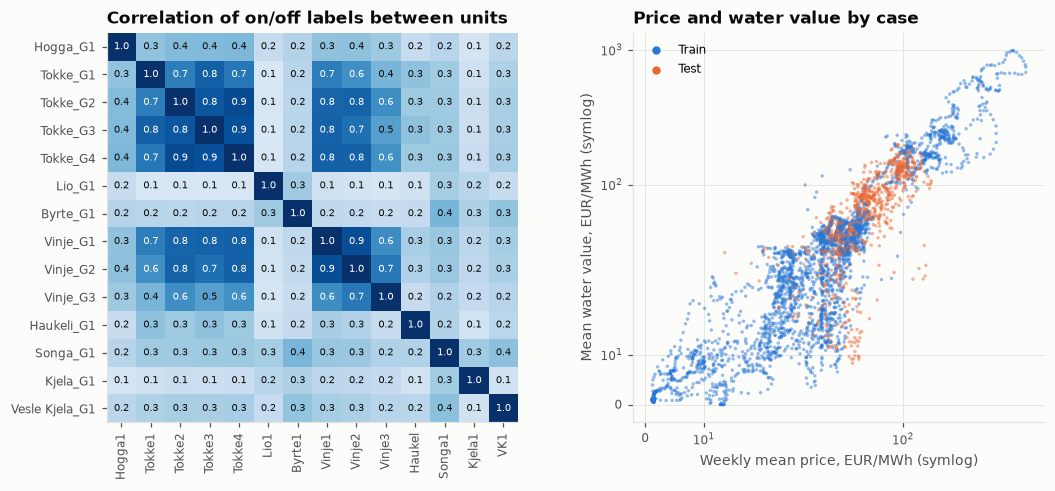

Correlation between weekly mean price and mean water value: 0.93
Correlation between reservoirs' water values, min and median: 0.76 0.88
Share of hours with a non-zero minimum flow: {'b_Kjelavatn': 1.0, 'b_Hyljelihyl': 1.0, 'b_Vinjevatn': 1.0, 'b_Byrtevatn': 0.34, 'b_Bandak': 1.0, 'r_Vest_Vassdraget': 1.0}
Share of hours with a non-zero minimum volume: {'Totak': 0.34, 'Byrtevatn': 0.13, 'Staavatn': 0.26}
Reservoir fill, mean over days: {'Kjelavatn': 0.5, 'Staavatn': 0.57, 'Langesae': 0.7, 'Foersvatn': 0.58, 'Venemo': 0.71, 'Botnedalsvatn': 0.6, 'Bitdalsvatn': 0.71, 'Vaamarvatn': 0.54, 'Langeidvatn': 0.71, 'Totak': 0.65, 'Songavatn': 0.66, 'Vinjevatn': 0.68, 'Bandak': 0.76, 'Bordalsvatn': 0.72, 'Byrtevatn': 0.72, 'Hyljelihyl': 0.5, 'Vatjern': 0.5}


In [7]:
wvc = np.corrcoef(wv.T)
labc = np.corrcoef(Y.transpose(1, 0, 2).reshape(14, -1))
vmat = np.array(pd.read_csv("data/kernel/Historical_volume_2015_2024.csv", index_col=0)[RES])
mx = np.array([float(TOPO.res[r]["max_vol"]) for r in RES])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(wspace=.28))
heat(ax[0], labc, [u.replace("_G", "") .replace("Vesle Kjela", "VK")[:6] for u in UNITS], UNITS, "Correlation of on/off labels between units", -.1, 1, "{:.1f}", size=6.5)
ax[0].tick_params(axis="x", rotation=90)
ax[1].scatter(P.mean(1), wv.mean(1), s=5, c=np.where(np.arange(len(P)) < N_TR, BLUE, ORANGE), alpha=.5, linewidths=0)
ax[1].set_xscale("symlog", linthresh=30)
ax[1].set_yscale("symlog", linthresh=30)
ax[1].set_xlabel("Weekly mean price, EUR/MWh (symlog)")
ax[1].set_ylabel("Mean water value, EUR/MWh (symlog)")
ax[1].set_title("Price and water value by case")
for lab, col in (("Train", BLUE), ("Test", ORANGE)):
    ax[1].scatter([], [], s=20, c=col, label=lab)
ax[1].legend()
plt.show()
print("Correlation between weekly mean price and mean water value:", round(float(np.corrcoef(P.mean(1), wv.mean(1))[0, 1]), 2))
print("Correlation between reservoirs' water values, min and median:", round(float(wvc.min()), 2), round(float(np.median(wvc)), 2))
print("Share of hours with a non-zero minimum flow:", {k: round(float(v), 2) for k, v in zip(MINFLOW, (c["minflow"] > 0).mean((0, 1)))})
print("Share of hours with a non-zero minimum volume:", {k: round(float(v), 2) for k, v in zip(MINVOL, (c["minvol"] > 0).mean((0, 1)))})
print("Reservoir fill, mean over days:", {k: round(float(v), 2) for k, v in zip(RES, (vmat / mx).mean(0))})

- **Units that share water run together.** Units in the same plant are strongly correlated, and so are Tokke and Vinje (0.4-0.8), which are linked through the water system. Other pairs are weakly correlated (0.1-0.4). This motivated a model that looks at all units at once (ST-Net) and features that describe neighbouring plants.
- **Water values move together.** Water values in different reservoirs correlate at 0.76 or more (median 0.88). The information lies mostly in their differences, not in their levels.
- **The rules follow the calendar.** Minimum flow and volume rules mostly change with the season, and they added little as separate columns (E004, R3). They matter through the water balance, which the LP handles directly.
- **Test cases mostly lie in the same price and water value range as training cases** (right figure).

**Adversarial validation.** To test the last point more strictly, I trained a classifier to tell test hours from training hours. If it cannot (AUC near 0.5), the test years look like the training years. Training and validation alternate in 60-day blocks, so overlapping cases stay together. Calendar and unit columns are left out, since dates alone would let the classifier memorise which period is test.

In [8]:
dr = json.load(open("artifacts/drift.json"))
display(pd.DataFrame(dr).T.assign(auc=lambda d: d.auc.astype(float).round(3)).rename_axis("Feature set").rename(columns={"n": "columns", "auc": "adversarial AUC", "top": "most used columns"}))

,columns,adversarial AUC,most used columns
Feature set,,,
with_absolute,62,0.953,"[week_price_iqr_asinh, week_price_mean_asinh, price_asinh, econ_frac_wv, ls_week_cheap, lp_margin_ratio]"
no_absolute,56,0.923,"[lp_switches, price_over_wv_up, start_hours_wv, lp_margin_ratio, econ_frac_wv, ls_week_band]"
lp_only,42,0.861,"[lp_switches, lp_margin_ratio, lp_sys_t, ls_week_band, ls_week_cheap, ls_week_dear]"
absolute_only,6,0.922,"[week_price_iqr_asinh, week_price_mean_asinh, price_asinh, lp_be_asinh, wv_down_asinh, wv_up_asinh]"


No feature set comes close to 0.5: the test years are clearly different, so every model has to extrapolate. Without the absolute price columns the classifier's AUC falls from 0.953 to 0.923, and the LP columns alone give 0.861, the most similar between the two periods. A first version that included calendar columns gave impossible results (a larger feature set scoring below a subset of itself), which exposed the memorisation and led to the setup above. Drift did not decide anything by itself: the neural network kept the absolute price columns because validation favoured them (Section 5.3).

### 3.6 Clean up features

- **No missing values or duplicates** inside any case window, checked for all 3647 cases. Labels are strictly 0 or 1, so nothing had to be imputed.
- **Two constant reservoirs.** Volumes for Hyljelihyl and Vatjern have no records and are fixed at 50 % full. As a result, `fill_up` (how full the reservoir above the plant is) carries no information for Haukeli, and `fill_down` none for Kjela. I kept them: trees ignore constant columns, and the LP models the full water balance anyway.
- **Time zone.** The files are in UTC, but the power market follows Norwegian time, so hour-of-day and weekday features use Oslo time.
- **Scaling.** Absolute levels use `asinh(x/10)`. Columns relative to the case, such as price compared with the week's median, are divided by the week's interquartile range, so weeks with very different price levels become comparable. Inputs to the neural network are standardised on the training fold and clipped to ±6 standard deviations, which limits the effect of extreme prices.
- **Removing features** was decided by testing, through the gate (Section 5.3).

## 4. Validation: how I measured progress

With AUCs above 0.99, real improvements are often only a few ten-thousandths. A reliable way to measure them was therefore as important as the models themselves. I used two validation schemes, one acceptance rule and one sanity check. The folds, the metric code and the rule are stored with SHA-256 hashes that are checked on every run, so they could not change by accident during the project.

- **Leave one year out (LOYO).** Eight folds, one per year 2015-2022. Cases overlap by six days, so training cases within 7 days of the validation year are removed (*purged*). Otherwise the model would see the same hours in both training and validation.
- **Forward validation.** Train only on years before 2019, 2020, 2021 and 2022, and predict that year. This is closest to the real situation, where the test years come after all training data. Its weakness is that it trains on fewer years.
- **The gate.** A change was accepted only if (1) the LOYO gain was larger than the seed noise (0.0001, measured by training XGBoost with five different seeds), (2) at least 6 of 8 years improved, (3) forward validation did not get worse by more than the noise, and (4) the code was committed, so the result can be reproduced. I wrote each hypothesis in the experiment log before the run, so a result could not change what I claimed to be testing.
- **Label control.** Training on labels shuffled between whole cases should give no more than base rates allow. It gives 0.589 on LP v4 (R2) and 0.592 on LP v2 (Section 6.2), so no leakage from the features is visible.

For earlier blends the weights were nested. The final weight was not (Section 7).

## 5. Feature engineering
### 5.1 Feature extraction: the LP surrogate

**Why an LP.** SHOP's decisions depend on the whole system at once: if one plant runs, the reservoir below fills up, which changes what the next plant should do. Hand-made features can capture parts of this, and that is what I did first (Phase 1, Section 6.1), but each feature covers one relationship. An optimisation model captures all of them together. I therefore built a simplified version of SHOP's problem that can be solved in a few seconds: a *linear program* (LP), in which a unit's on/off decision may take any value between 0 and 1 instead of only 0 or 1. Its solution, the LP's plan, is given to the machine-learning models as features, and the models learn the difference between the simplified plan and SHOP's real one.

**What the LP solves.** For each case it maximises

$$\underbrace{\sum_t \lambda_t \sum_g P_{g,t}}_{\text{income from selling power}} \; + \; \underbrace{\sum_r v_r V_{r,168}}_{\text{value of water left at the end}} \; - \; \text{flow costs} \; - \; \text{start costs}$$

where $\lambda_t$ is the price in hour $t$, $P_{g,t}$ the power from unit $g$, $V_{r,168}$ the volume left in reservoir $r$ after the week and $v_r$ the value of that water. The water balance must hold in all 17 reservoirs every hour, together with volume limits, minimum flows and minimum volumes. For each unit, power is a concave piecewise-linear function of flow, built from the turbine and generator curves in the system's YAML file at the head given by the start volume, including losses in pipes and shared tunnels. Head is held fixed through the week. Water sent down the four main rivers costs more per m3/s the more is sent, following the convex cost curve in the YAML file. One unit, Lio, gets a whole on/off decision (0 or 1); all other units keep values between 0 and 1 (see the end of this section).

The LP has no trained parameters. The only thing taken from the labels is the start order of identical units (Section 3.2). I did, however, compare LP versions by scoring them against the labels, which is a form of selection (Section 12).

**The key decision: what water left in a reservoir is worth.** The data gives a water value $w_r$ in EUR/MWh for each reservoir. The LP needs a value per cubic metre, and the conversion is not obvious. Consider two reservoirs in series: water from reservoir A runs through plant 1 into reservoir B, and from B through plant 2 out of the system. Let $c_1$ and $c_2$ be the energy each plant produces per cubic metre.

- With *telescoping* values, my final choice, a cubic metre in B is worth $w_B c_2$. A cubic metre in A is worth $w_A c_1$ **plus** what the same water is worth once it reaches B: $w_A c_1 + w_B c_2$.
- Running plant 1 on one cubic metre then earns $\lambda c_1$, uses water worth $w_A c_1 + w_B c_2$ from A, and adds water worth $w_B c_2$ to B. The net gain is $c_1(\lambda - w_A)$: plant 1 should run exactly when the price is above the water value of the reservoir directly above it, which is the rule from Section 3.1.

In general, the value of a cubic metre in reservoir $r$ is

$$\text{value}(r) = w_r \cdot c(\text{first plant below } r) + \text{value}(\text{reservoir below that plant}).$$

The two readings I tried first make a plant's decision depend on the water values of other reservoirs in a way that breaks this rule. The table shows how much the choice mattered, together with the later improvements of the LP.

| LP version | What changed | AUC of the LP's on/off value, no training | AUC of the LP's power fraction, no training |
|---|---|---|---|
| `lp_local` | Water valued with the plant directly below only | 0.6062 | 0.6495 |
| `lp_global` | Water valued with all plants down the cascade | 0.7431 | 0.7581 |
| `lp_tele` | Telescoping values | 0.9323 | 0.9470 |
| `lp_v2`, `lp_v3` | Curves per unit, head losses, start order | 0.9442, 0.9558 | 0.9561, 0.9688 |
| `lp4_b10` | Corrected Tokke start order, river costs, bypass cost 10 | 0.9576 | 0.9705 |
| `lp4_b100`, `lp4_b1000` | Higher cost for water bypassing the plants | 0.9527, 0.9517 | 0.9656, 0.9646 |
| `milp_v2`, `mp4_b10` | Whole on/off decisions (integer program) on v2 and v4 | 0.9296, 0.9441 | 0.9445, 0.9606 |
| **`lp5q`, final (v5)** | Full river cost curve, whole on/off decisions for Lio only | **0.9574** | **0.9709** |

Scores are on all 2922 training cases, with no model trained. The *power fraction* (power divided by maximum power) ranks a little better than the on/off value, so both are used as features. The telescoping step (0.743 to 0.932) is by far the largest. Forcing whole on/off decisions for all units (an integer program, MILP) made the plan worse, and its features did not help the trees (L3). The final features use three solves per case: the water values as given, and scaled by 0.9 and 1.1 (Section 5.2).

**Version 5: two corrections found late.** Comparing the LP's plan with SHOP's unit by unit, late in the project, showed two places where the LP solved a different problem from SHOP:

1. *River costs.* The four main rivers have a flow cost curve in the YAML file. SHOP's documentation describes it as piecewise constant: the cost per m3/s is 1 up to 40 m3/s, 65 from 40 to 100, 239 from 100 to 200, and so on. Version 4 read the curve as a total cost and charged its first slope, (65 - 1) / 40 = 1.6 per m3/s, at every flow, so it sent more than 40 m3/s down the river below Hyljelihyl in 23 % of hours. Version 5 uses the whole curve, which brings this to 0.3 %.
2. *Lio and the minimum flow.* Lio's water goes to `r_Vest_Vassdraget`, which has a minimum flow. With on/off relaxed, the LP met that minimum by running Lio partly "on" in 29 % of Lio's hours (the middle half of these values lie between 0.30 and 0.41), and in 87 % of those hours below Lio's minimum output of 14.8 MW. SHOP cannot do this. Version 5 makes Lio's 168 on/off values whole numbers, solves that small integer problem, fixes Lio's schedule and solves the LP again to get the shadow prices used as features.

Version 5 ranks about as well as version 4 on its own (table above), but its weekly level is closer to SHOP's: the mean absolute error of each unit's weekly on-share falls from 0.044 to 0.037, and the share of correct hours rises from 0.943 to 0.952. Only Lio is made integer, because only Lio had this problem; the full MILP above made every unit integer and was worse. The integer step is solved to HiGHS's default relative gap of 0.01 %. Solving it to proven optimality was not practical: 4 of 3647 cases did not finish in 10 minutes, so the result would depend on the computer's speed (Section 11).

The table below lists the feature groups of the final models. The six absolute price columns printed under it are used only by the neural network in notebook 1.

In [9]:
interp = json.load(open("artifacts/interp_final.json"))
G = interp["groups"]
display(pd.DataFrame([dict(group=k, columns=len(v), examples=", ".join(v[:7]) + (" ..." if len(v) > 7 else "")) for k, v in G.items()]).set_index("group"))
print("Dropped from trees (ST-Net in notebook 1 keeps them):", open("artifacts/scale_cols.txt").read().strip())

,columns,examples
group,,
market,10,"price_asinh, price_z, price_rank_week, price_rank_day, price_diff_prev, price_diff_next, price_dev_7h ..."
calendar,5,"hour_local, weekday_local, doy_sin, doy_cos, horizon_hour"
unit,5,"unit_id, plant_id, unit_index, p_max, start_per_mw"
lp_schedule,36,"lp_u, lp_p, lp_margin, lp_margin_ratio, lp_be_asinh, lp_be_gap_wv, lp_u_prev1 ..."
lp_sensitivity,7,"ls_u_cheap, ls_u_dear, ls_band, ls_week_cheap, ls_week_dear, ls_week_band, ls_mean"
water_state,9,"wv_up_asinh, wv_down_asinh, fill_up, fill_down, inflow_up_asinh, margin_wv_up, price_over_wv_up ..."


Dropped from trees (ST-Net in notebook 1 keeps them): price_asinh,week_price_mean_asinh,week_price_iqr_asinh,wv_up_asinh,wv_down_asinh,lp_be_asinh


### 5.2 Features built on the LP

The models need more than the LP's plan itself. They also need to know where the plan is likely to be wrong, so the plan is turned into features in several ways:

- **LP schedule (`lp_*`, 36 columns).** The LP's on/off value and power for each unit and hour, the same values in the hours before and after, rolling means, and the hours to the nearest switch. Also the LP's *marginal cost* of running, taken from its shadow prices: `lp_margin` is the price minus this cost and `lp_margin_ratio` their ratio. These tell the model how close the LP was to switching. Further columns describe output per plant, neighbouring plants and the whole system, reservoir levels through the week, and water bypassing the plants.
- **LP sensitivity (`ls_*`, 7 columns).** The LP solved again with all water values x0.9 and x1.1. If a decision changes between these solves, it was a near-tie, and near-ties are where the LP most often disagrees with SHOP. `ls_mean` is the average of the three plans.
- **Market and calendar (15 columns).** Price rank within the week and the day, deviations from rolling means, and local hour, weekday and season.
- **Unit and water state (14 columns).** Which unit and plant, capacity, start cost per MW, price compared with water value, and how full the reservoirs are and how much water flows into them.

In Phase 1, before the LP, I built hand-made features for break-even prices, hydraulic state, neighbouring plants and system state (Section 6.1). The LP features replaced them.

### 5.3 Feature selection

Every change to the feature set went through the gate (Section 4), using XGBoost or ST-Net with 3 seeds unless noted. The table shows the LOYO score, the change against the reference in LOYO and forward validation (`d LOYO`, `d forward`), and the decision. Two column groups appear by name: `mf_*`, the water flow that the minimum flow rules require, and `lps_*`, the LP's weekly output for each plant.

In [10]:
def row(n, ref=None):
    r = rows[n]
    return r["oof_auc"], (r["oof_auc"] - rows[ref]["oof_auc"]) if ref else np.nan
T = [("Add ls_* (trees)", "XR_ls", "XR_min", "XR_ls_f", "XR_min_f", "Accepted. 66 features, 7/8 years"),
     ("Add ls_*, keep mf_*, lps_* (trees)", "XR_sens2", "XR_ref", "XR_sens_f2", "XR_ref_f", "Passes, but no better than the row above with 13 fewer features"),
     ("Drop mf_* constraint columns (trees)", "XR_nomf", "XR_ref", "XR_nomf_f", "XR_ref_f", "Inside noise, dropped for simplicity"),
     ("Drop lps_* plant shares (trees)", "XR_nolps", "XR_ref", "XR_nolps_f", "XR_ref_f", "Inside noise, dropped for simplicity"),
     ("Drop both (trees)", "XR_min", "XR_ref", "XR_min_f", "XR_ref_f", "No change, 59 vs 72 features"),
     ("Keep absolute price columns (trees)", "XR_scale", "XR_ref", "XR_scale_f", "XR_ref_f", "Inside noise, so left out of the trees"),
     ("Keep absolute price columns (net)", "N4_v4_scale", "N3_v4_mf", "N4f_e24_scale", "N3f3_e24", "Forward +0.0007 (mostly 2020), LOYO within net seed noise. Kept in the net in notebook 1"),
     ("base,lp,ls only (net)", "N6_min", "N4_v4_scale", "N6f_min", "N4f_e24_scale", "Accepted. 7/8 years, 4/4 forward"),
     ("Add ls_*, keep mf_*, lps_* (net)", "N5_ls", "N4_v4_scale", "N5f_ls", "N4f_e24_scale", "Fails, 4/8 years"),
     ("Drop absolute price columns again (net, hedge)", "N7_noabs", "N6_min", "N7f_noabs", "N6f_min", "Fails the gate by design. Used as the hedge in notebook 2"),
     ("LP v5 instead of v4 (trees, CPU)", "XR5c_ls", "XRc_ls", "XR5c_ls_f", "XRc_ls_f", "Accepted. 8/8 years, 4/4 forward"),
     ("LP v5 instead of v4 (net, CPU)", "N6c_v5", "N6c_v4", "N6fc_v5", "N6fc_v4", "Accepted. 7/8 years (2015 equal), 4/4 forward"),
     ("LP v5 instead of v4 (net without absolute prices, CPU)", "N7c_v5", "N7c_v4", "N7fc_v5", "N7fc_v4", "Passes, 8/8 years, 4/4 forward. Hedge in notebook 2")]
display(pd.DataFrame([{"Change": a, "LOYO": rows[n]["oof_auc"], "d LOYO": rows[n]["oof_auc"] - rows[rf]["oof_auc"], "d forward": rows[nf]["oof_auc"] - rows[rff]["oof_auc"], "columns": rows[n].get("n_features"), "Decision": note} for a, n, rf, nf, rff, note in T]).round(5).set_index("Change"))

,LOYO,d LOYO,d forward,columns,Decision
Change,,,,,
Add ls_* (trees),0.99349,0.00023,0.00037,66,"Accepted. 66 features, 7/8 years"
"Add ls_*, keep mf_*, lps_* (trees)",0.99349,0.00023,0.00035,79,"Passes, but no better than the row above with 13 fewer features"
Drop mf_* constraint columns (trees),0.99325,-0.00001,-0.00007,68,"Inside noise, dropped for simplicity"
Drop lps_* plant shares (trees),0.99321,-0.00005,-0.00006,63,"Inside noise, dropped for simplicity"
Drop both (trees),0.99326,0.00000,0.00000,59,"No change, 59 vs 72 features"
Keep absolute price columns (trees),0.99328,0.00003,0.00004,78,"Inside noise, so left out of the trees"
Keep absolute price columns (net),0.99270,0.00023,0.00070,76,"Forward +0.0007 (mostly 2020), LOYO within net seed noise. Kept in the net in notebook 1"
"base,lp,ls only (net)",0.99334,0.00064,0.00083,70,"Accepted. 7/8 years, 4/4 forward"
"Add ls_*, keep mf_*, lps_* (net)",0.99276,0.00006,0.00017,83,"Fails, 4/8 years"


Two results surprised me:

- **Absolute price levels helped the network on LP v4, not the trees.** I expected that removing them would help everywhere, since they are what drifts most between training and test years. For the trees they made no difference, so I left them out. For the neural network they raised forward AUC by 0.0007, mostly through 2020, so the network in notebook 1 keeps them. The LOYO gain (+0.00023) was smaller than the network's seed noise (up to 0.00035, Section 7), so the evidence rests on forward validation. On LP v5 the difference is gone: without these columns the network scores 0.99366 against 0.99373 in LOYO and 0.99323 against 0.99307 in forward validation (Section 6.2). Notebook 2 hedges this decision.
- **Fewer columns helped the network.** Adding `ls_*` while keeping `mf_*` and `lps_*` failed for the network (4/8 years). Adding `ls_*` and removing those two passed clearly (+0.00064 LOYO, 7/8 years, 4/4 forward years). For the trees the two groups made no difference either way, so both final models use the smaller set `base,lp,ls`.

**LP v5 helped every model.** The last three rows compare the same models on LP v5 and LP v4 (Section 5.1). Both versions were trained on CPU nodes for this comparison, since no GPU was available at the end of the project; the CPU runs on LP v4 reproduce the earlier GPU runs within 0.00002, so the two sets are comparable. LP v5 raised XGBoost, the network and the hedge network by about 0.0004 each in LOYO, all passing the gate, and the notebook 1 blend by 0.0003 in both LOYO and forward validation (3 of 4 forward years; 2019 fell by 0.00003). The LP's own AUC barely changed (0.9576 to 0.9574), so that number was a poor guide to which LP helps the models. Per unit, Kjela gains most (blend 0.9889 to 0.9914), followed by Haukeli and Lio (+0.0006 each). The weakest unit-year on LP v4, Lio in 2022, rose from 0.964 to 0.980, which fits the Lio correction.

**The public leaderboard agreed.** I accepted LP v5 by the rule above before the new files were submitted. Their public scores came afterwards and rose by about 0.00013 for both notebooks (notebook 1 from 0.99638 to 0.99651). That is smaller than in validation (about +0.0003), but in the same direction, on test years the LP's design never saw.

## 6. All models and algorithms tried

The project had two phases. In Phase 1 I engineered features by hand and tried many model types. In Phase 2 the LP features were added, and the same model types were tested again on them. Every row below is a logged run.

### 6.1 Phase 1: without the LP

Scores are LOYO AUC over all 8 years, except rows marked *tuning*, which used only three folds (2018, 2020, 2022) for screening. Values with a sign are changes against the reference on those folds. The gate's noise level in this phase was 0.00084.

What the phase showed: gradient-boosted trees (LightGBM, XGBoost) clearly beat logistic regression and random forest; features built from domain knowledge (break-even prices, hydraulic state, neighbouring plants) gave the largest gains; and a neural network, whose errors differ from the trees', gave a further jump when blended with them. The best result was E021a, LightGBM + ST-Net, at 0.98584.

| Id | Model or idea | AUC | Outcome |
|---|---|---|---|
| E000 | LightGBM, base features | 0.95415 | Reference. Weakest year 2020 (0.92178) |
| E006 | Logistic regression (25 % of rows) | 0.89708 *tuning* | Baseline |
| E006 | Random forest (10 % of rows) | 0.93927 *tuning* | Baseline. LightGBM has 0.94791 on these folds |
| E007 | XGBoost | 0.94888 *tuning* | Correlated 0.98 with LightGBM, so no gain from blending them |
| E001 | Break-even price per plant | 0.95701 | Accepted, 8/8 years |
| E002 | Separate model for the weekly level first | -0.00163 *tuning* | Rejected, all folds worse |
| E003 | Hydraulic state in hours of full capacity | 0.96009 | Accepted, 8/8. 2020 +0.016 |
| E004 | Inflow anomaly, constraint columns | -0.00029 *tuning* | Rejected, inside noise |
| E005 | Monotone constraints on price | +0.00068 *tuning* | Rejected, below noise |
| E008 | UC-Net: neural network with dilated convolutions, Transformer, FiLM, start-order and auxiliary outputs | 0.95893 | Its errors differ from LightGBM's |
| E009 | E001 + E003 | 0.96295 | Accepted. Public 0.97252 |
| E010 | No absolute price levels | 0.96409 | Gate fail, 4/8. Better only in extreme years |
| E011 | Optuna tuning of LightGBM | 0.96389 | Rejected. The 5 folds not used for tuning averaged -0.00014 |
| E012 | LightGBM + UC-Net, nested blend | 0.97847 | Accepted. Public 0.98506 |
| E013 | Economics of neighbouring plants, spill pressure | 0.97919 | Accepted, +0.016, 8/8 |
| E014 | E013 + UC-Net, nested blend | 0.98254 | Accepted. Public 0.98845 |
| E015 | UC-Net, 3 nets per seed | 0.96461 | Passes. Lower variance |
| E018 | UC-Net on E013 features | 0.96019 | Passes. Replaced by ST-Net |
| E019 | ST-Net: one token per (unit, hour), attention across units | 0.98199 (3-seed ensemble 0.98425) | Accepted. Alone beats E014 |
| E020 | Blend weights per plant | 0.98345 | Passes, barely above noise |
| E021a | E013 + ST-Net, nested blend | **0.98584** | Best without the LP. Public **0.98906** |
| E021b | E013 + ST-Net + UC-Net, nested blend | 0.98597 | Below noise, not used |
| - | Averaging predictions across overlapping cases | 0.98151 | Rejected, worse in 8/8 |
| E022 | ST-Net, 3 other seeds | 0.98187 (3-seed ensemble 0.98407) | Six seeds add nothing measurable |
| E023 | ST-Net on E013 features | -0.00042 *tuning* | Rejected |
| E024 | ST-Net with a pairwise ranking loss | -0.00034 *tuning* | Rejected |
| E025 | Blend weights per plant on E021a | 0.98604 | Rejected, below noise |
| E026 | LightGBM with the state of the whole water system | 0.98118 | Accepted alone. Rejected as notebook 2, about 0.012 below the final blend |
| E027 | E026 + ST-Net | 0.98608 | Below noise |
| - | E021a + the LP's prediction (`lp_v3`, weight 0.5), no retraining | 0.98974 | First sign that the LP adds information. Replaced by LP features inside the models |

### 6.2 Phase 2: with the LP

With the LP features in place, I tested the same model types again. The numbers are read from the experiment log, in the order the runs were made, each under its run ID. `LOYO` and `Forward` are the two validation schemes from Section 4, and a dash means the run was not made in that scheme. *e24* means 24 training epochs.

In [11]:
DESC = [("L0_base", "L0_base_fwd", "LightGBM", "No LP, base features", "Reference for what the LP adds. New code, 29 features, 1 seed, so not identical to E000"),
    ("L1_base_lp", None, "LightGBM", "Base + LP telescoping", "+0.037. By far the largest step in the project"),
    ("L2_v2", "L2_v2_fwd", "LightGBM", "LP v2", "Adopted"),
    ("L2_v2_shuffle", None, "LightGBM", "LP v2, labels shuffled", "Control, about 0.59 as expected"),
    ("L3_v2_milp", None, "LightGBM", "LP v2 + integer MILP schedule", "Rejected, no gain"),
    ("L4_noscale", None, "LightGBM", "LP v2, no absolute prices", "-0.00017, small loss"),
    ("L5_v3", None, "LightGBM", "LP v3", "Adopted"),
    ("L6_v3_noscale", None, "LightGBM", "LP v3, no absolute prices", "Inside noise"),
    ("L7_v4_mf", None, "LightGBM", "LP v4 + required flow columns", "Adopted LP v4"),
    ("L8_v4", None, "LightGBM", "LP v4", "Reference"),
    ("L9_v4_mf_s3", "L10f", "LightGBM", "LP v4 + mf_*, 3 seeds", "Blend member in B2"),
    ("X1_v4_mf", "X1f_fwd", "XGBoost", "Same features", "Blend member in B2. Fast on GPU, so became the main tree"),
    ("C1_v4_mf", "C2f", "CatBoost", "Same features", "Blend member in B2. Weak forward, dropped later"),
    ("N1_stnet_lp", None, "ST-Net", "LP v2, 1 seed", "First LP net"),
    ("N2_stnet_v3", None, "ST-Net", "LP v3, 2 seeds", "Improves with the LP"),
    ("N3_v4_mf", "N3f3_e24", "ST-Net", "LP v4, no absolute prices, e24", "Blend member in B2"),
    ("N4_v4_scale", "N4f_e24_scale", "ST-Net", "With absolute prices, e24", "Blend member in B2. Forward +0.0007"),
    ("N8_e12", "N8f_e12", "ST-Net", "No absolute prices, e12", "Rejected. 12 epochs worse in LOYO"),
    ("N9_e12_scale", "N9f_e12_scale", "ST-Net", "With absolute prices, e12", "Rejected, R20: e24 wins on same seeds"),
    (None, "N10f_e8", "ST-Net", "e8", "Rejected, too few epochs"),
    (None, "N11f_e16", "ST-Net", "e16", "Equal to e24 without prices. Not pursued"),
    (None, "N12f_d96", "ST-Net", "d=96 instead of 64", "Rejected, R15, 1/4 years"),
    ("N5_ls", "N5f_ls", "ST-Net", "Keep all + ls_*", "Gate fail, R19"),
    ("N6_min", "N6f_min", "ST-Net", "base,lp,ls", "Accepted. Final net on LP v4"),
    ("N7_noabs", "N7f_noabs", "ST-Net", "base,lp,ls, no absolute prices", "Hedge on LP v4"),
    (None, "P1f_pseudo", "XGBoost", "Pseudo-labels from validation year", "Rejected, no gain over the same XGBoost without them (0.99297)"),
    ("XR_ref", "XR_ref_f", "XGBoost", "Clean reference, 72 columns, 5 seeds", "Gate reference, seed noise measured here"),
    ("XR_r800", "XR_r800_f", "XGBoost", "eta 0.04, 800 rounds", "Rejected, R13, inside noise"),
    ("XR_ls", "XR_ls_f", "XGBoost", "base,lp,ls, no absolute prices", "Accepted. Final trees on LP v4"),
    ("XRc_ls", "XRc_ls_f", "XGBoost (CPU)", "As XR_ls, trained on CPU", "LP v4 reference for v5. Within 0.00002 of XR_ls"),
    ("N6c_v4", "N6fc_v4", "ST-Net (CPU)", "As N6_min, trained on CPU", "LP v4 reference for v5. Within 0.00001 of N6_min"),
    ("N7c_v4", "N7fc_v4", "ST-Net (CPU)", "As N7_noabs, trained on CPU", "LP v4 reference for v5. Equal to N7_noabs"),
    ("XR5c_ls", "XR5c_ls_f", "XGBoost (CPU)", "base,lp,ls on LP v5", "Accepted. Final trees"),
    ("N6c_v5", "N6fc_v5", "ST-Net (CPU)", "base,lp,ls on LP v5", "Accepted. Final net, notebook 1"),
    ("N7c_v5", "N7fc_v5", "ST-Net (CPU)", "base,lp,ls on LP v5, no absolute prices", "Hedge, notebook 2")]
num = lambda n: f"{rows[n]['oof_auc']:.5f}" if n else "-"  # "-": not run in that validation scheme
tab = pd.DataFrame([dict(Run=a or b, Model=m, Features=f, LOYO=num(a), Forward=num(b), Note=n) for a, b, m, f, n in DESC]).set_index("Run")
display(tab)

,Model,Features,LOYO,Forward,Note
Run,,,,,
L0_base,LightGBM,"No LP, base features",0.95515,0.94877,"Reference for what the LP adds. New code, 29 features, 1 seed, so not identical to E000"
L1_base_lp,LightGBM,Base + LP telescoping,0.99215,-,+0.037. By far the largest step in the project
L2_v2,LightGBM,LP v2,0.99267,0.99212,Adopted
L2_v2_shuffle,LightGBM,"LP v2, labels shuffled",0.59233,-,"Control, about 0.59 as expected"
L3_v2_milp,LightGBM,LP v2 + integer MILP schedule,0.99253,-,"Rejected, no gain"
L4_noscale,LightGBM,"LP v2, no absolute prices",0.99250,-,"-0.00017, small loss"
L5_v3,LightGBM,LP v3,0.99313,-,Adopted
L6_v3_noscale,LightGBM,"LP v3, no absolute prices",0.99312,-,Inside noise
L7_v4_mf,LightGBM,LP v4 + required flow columns,0.99319,-,Adopted LP v4


The figure below puts both phases on one axis. The axis is logarithmic in the error, 1 - AUC, so that the models near the top can be told apart: each step on the axis is the same relative reduction in error.

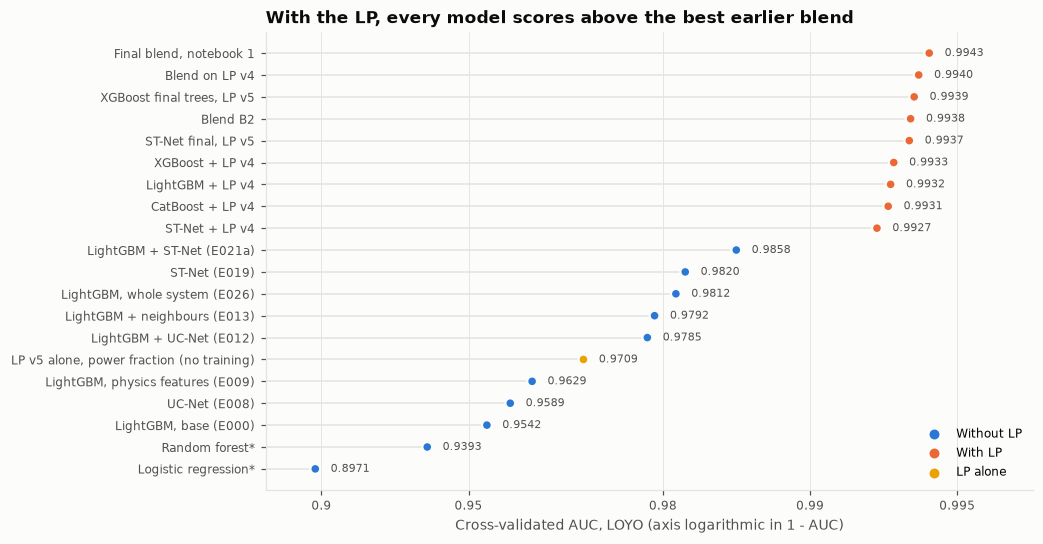

* Three tuning folds only, not all 8 years, so not directly comparable with the others.


In [12]:
pts = [("Logistic regression*", .89708, 0), ("Random forest*", .93927, 0), ("LightGBM, base (E000)", .95415, 0), ("LP v5 alone, power fraction (no training)", auc(Y, LPF[:N_TR]), 2), ("UC-Net (E008)", .95893, 0), ("LightGBM, physics features (E009)", .96295, 0), ("LightGBM + neighbours (E013)", .97919, 0), ("LightGBM, whole system (E026)", .98118, 0), ("ST-Net (E019)", .98199, 0), ("LightGBM + UC-Net (E012)", .97847, 0), ("LightGBM + ST-Net (E021a)", .98584, 0),
    ("LightGBM + LP v4", rows["L8_v4"]["oof_auc"], 1), ("CatBoost + LP v4", rows["C1_v4_mf"]["oof_auc"], 1), ("XGBoost + LP v4", rows["XR_ref"]["oof_auc"], 1), ("ST-Net + LP v4", rows["N4_v4_scale"]["oof_auc"], 1), ("XGBoost final trees, LP v5", rows["XR5c_ls"]["oof_auc"], 1), ("ST-Net final, LP v5", rows["N6c_v5"]["oof_auc"], 1), ("Blend B2", rows["B2_gbdt3_nn2_nested"]["oof_auc"], 1), ("Blend on LP v4", auc(Y, B4), 1), ("Final blend, notebook 1", auc(Y, B), 1)]
pts = sorted(pts, key=lambda p: p[1])
cols = [BLUE, ORANGE, YELLOW]
fig, ax = plt.subplots(figsize=(9, 5.4))
err = [1 - p[1] for p in pts]  # plotted as error 1 - AUC on a log axis
ax.set_xscale("log")
ax.set_xlim(.13, .0035)
ticks = [.1, .05, .02, .01, .005]
ax.set_xticks(ticks, [f"{1 - t:g}" for t in ticks])
ax.minorticks_off()
ax.hlines(range(len(pts)), .13, err, color=GRID, lw=1)
ax.scatter(err, range(len(pts)), s=42, c=[cols[p[2]] for p in pts], zorder=3, edgecolors="#fcfcfb", linewidths=1.5)
ax.set_yticks(range(len(pts)), [p[0] for p in pts])
ax.set_xlabel("Cross-validated AUC, LOYO (axis logarithmic in 1 - AUC)")
ax.grid(axis="y", visible=False)
ax.set_title("With the LP, every model scores above the best earlier blend")
for k, p in enumerate(pts):
    ax.text(err[k] * .93, k, f"{p[1]:.4f}", va="center", fontsize=7.5, color=MUTED)
for lab, col in (("Without LP", BLUE), ("With LP", ORANGE), ("LP alone", YELLOW)):
    ax.scatter([], [], s=30, c=col, label=lab)
ax.legend(loc="lower right")
plt.show()
print("* Three tuning folds only, not all 8 years, so not directly comparable with the others.")

Every model with the LP features (orange) scores above the best blend from Phase 1. The model type matters much less than the features: with the LP, LightGBM, XGBoost, CatBoost and ST-Net all lie within 0.001 of each other.

**Choosing the blend.** Blends with weights chosen nested in forward validation (R16) gave 0.99329 for XGBoost + network, and 0.99334 when CatBoost was added, a difference below the noise level. Adding LightGBM or a network without price columns did not help either. I therefore kept the simplest blend: two members of different types, gradient-boosted trees (XGBoost) and a neural network (ST-Net). Their predictions correlate at 0.97 in log-odds, but the blend still matches or beats both on 13 of 14 units (Section 9).

**Ideas proposed but not run.** (P1) Creating training data with negative prices by pushing the cheapest hours below zero and labelling them with the LP, and (P2) scaling price and water values together as data augmentation. I judged both unlikely to help. Changing the inputs can change the correct label. Overlapping cases already act as shifted copies of each other. And cases labelled by the LP lack exactly the difference between SHOP and the LP that the models are meant to learn. P1 also could not be validated, since the validation years contain almost no negative prices.

## 7. Final models and hyperparameters

The course asks that the hyperparameters in the short notebooks are explained. For each value below, the *Origin* column says where it came from: tested, carried over from an earlier experiment, or set by hand. Most values were not tuned. Tuning LightGBM with Optuna (E011) gave no gain on the folds it was not tuned on, which suggested that more tuning would mostly fit noise. Feature work gave far larger gains, so that is where the effort went.

**XGBoost** uses 66 features (`base,lp,ls` without the six absolute price columns). Each training row is one (case, unit, hour). Three models with different seeds are averaged in log-odds.

| Parameter | Value | Origin |
|---|---|---|
| `learning_rate`, rounds | 0.08, 300 | From E000. R13 (0.04, 800) was inside noise |
| `max_leaves`, `grow_policy` | 63, lossguide | From E000. Optuna (E011) gave no gain outside its own folds, so I stopped tuning trees |
| `min_child_weight` | 50 | Rough counterpart to LightGBM's `min_data_in_leaf` of 500. Not tuned |
| `subsample`, `colsample_bytree`, `reg_lambda`, `max_bin` | 0.5, 0.8, 1.0, 255 | From E000. Not tuned |
| `max_depth` | 0 (no limit) | `max_leaves` sets tree size under lossguide |
| Seeds | 3 | Seed std is 0.00003 LOYO, 0.00006-0.00009 forward (R1) |

**ST-Net** uses 70 features (`base,lp,ls` without `unit_id` and `plant_id`, which a learned unit embedding replaces). It treats each (unit, hour) as a token, 14 units x 168 hours per case. Each of four blocks first looks along time with a dilated convolution and then lets the 14 units exchange information through attention. The dilations are 1, 2, 4 and 8, so later blocks see further back and ahead, and the convolution is conditioned on a summary of the unit's week. A Transformer layer over the week follows. The output layer enforces the start order of identical units from Section 3.2, and an auxiliary output predicts each unit's weekly on-share, which trains the network to also get the weekly level right.

| Parameter | Value | Origin |
|---|---|---|
| Epochs | 24 | Beats 12 epochs on two seed sets, in LOYO and forward (R20) |
| `d`, blocks, heads | 64, 4, 4 | Sized for repeated runs. d=96 was worse (R15, 1/4 years) |
| Dropout, weight decay | 0.1, 0.01 | From E019. Alternatives were within seed noise (see below the table) |
| Learning rate, batch, EMA | 1e-3, 32, 0.995 | From E008 and E019 |
| Warmup, decay, gradient clip | 5 % of steps, cosine, norm 1.0 | From E008 |
| Input clipping | ±6 standard deviations | Set by hand. Not tuned |
| Auxiliary weight | 0.3 | From E008 |
| Seeds | 3 | Seed sets differ by up to 0.00035 alone, but barely in the blend. Six add nothing (R14) |

*Dropout and weight decay.* Two alternatives were tried with one seed in forward validation: dropout 0.25 (+0.00016) and weight decay 0.1 with dropout 0.2 and 16 epochs (+0.0006), both against a one-seed run of the current values. That run was itself 0.0012 below the current values with 3 seeds (R10), so both gains are within seed noise. They were not repeated with 3 seeds, so the current values are kept, not shown to be best.

**LP.** Flow costs, start costs, curves and limits come from the system's YAML file, including the main rivers' flow cost curves. The remaining constants:

| Constant | Value | Origin |
|---|---|---|
| Bypass cost | 10 | YAML value. Swept over 10, 100, 1000 on the LP alone, and 10 was best |
| Curve segments per unit | 3 | Set by hand: keeps the start, the best-efficiency point and the end. Not swept |
| Two-way tunnels, Totak-Vaamarvatn and Bordalsvatn-Foersvatn | ±150, ±15 m3/s | Set by hand, since the YAML gives only a loss factor. Not swept |
| Minimum head difference for the Venemo-Totak tunnel limit | 0.5 m | Set by hand, keeps the limit above zero. Not swept |
| Sensitivity scale on water values | x0.9, x1.1 | Set before running. Not tuned |
| Units with whole on/off decisions | Lio only | Found by comparing the LP's plan with the labels (Section 5.1). Not swept over other units |
| Relative gap of Lio's integer step | 0.01 % | HiGHS default. A tighter gap did not finish on 4 cases within 10 minutes (Section 5.1) |
| Time limit per solve | 600 s for Lio's integer step, 120 s for the LP | Set by hand, far above normal solve times. Lio's integer step took at most 2 minutes and never reached its limit (Section 11) |
| Penalty for breaking a minimum volume | 500 000 EUR per Mm3 | Set by hand, far above any water value, so the LP breaks the rule only when it cannot be met. Not swept |
| Penalty for breaking a minimum flow | 2000 EUR per m3/s and hour | Set by hand. Not swept |

**Blend weight.** 0.7 for XGBoost and 0.3 for ST-Net, fixed before the last round of experiments. The table below shows that validation is flat between 0.6 and 0.8, and nested weights on an earlier set of models were 0.65-0.70 in every fold. The final weight itself was not chosen nested.

In [13]:
f = lambda a, b, w: w * a + (1 - w) * b
okf = np.isfinite(XF).all((1, 2))
W = [.5, .6, .7, .8, .9, 1.]
display(pd.DataFrame({"Tree weight": W, "LOYO": [auc(Y, f(XT, NT, w)) for w in W], "Forward": [auc(Y[okf], f(XF, NF, w)[okf]) for w in W]}).round(5).set_index("Tree weight").T)
print("Correlation between tree and net logits:", round(np.corrcoef(XT.ravel(), NT.ravel())[0, 1], 3))

Tree weight,0.5,0.6,0.7,0.8,0.9,1.0
LOYO,0.99431,0.99432,0.99430,0.99422,0.99408,0.99388
Forward,0.99398,0.99403,0.99404,0.99399,0.99389,0.99373


Correlation between tree and net logits: 0.968


## 8. Model interpretation

The goal here is to check that the models use the features for the reasons I intended, mainly the LP's plan, and to find out what they add to it. I use three methods that answer different questions:

- **SHAP** (8.1, 8.2): how much each feature pushes each single prediction up or down. Computed for the trees.
- **Partial dependence** (8.1): how the prediction changes on average when one feature is varied.
- **Permutation importance** (8.3): how much the score drops when a feature is scrambled. Computed for both models and the blend.

Sections 8.1-8.3 use the final model types, trained before 2022 and explained on 2022, which they did not see, with seed 0. Section 8.4 uses the out-of-fold LOYO blend.

### 8.1 SHAP on the trees

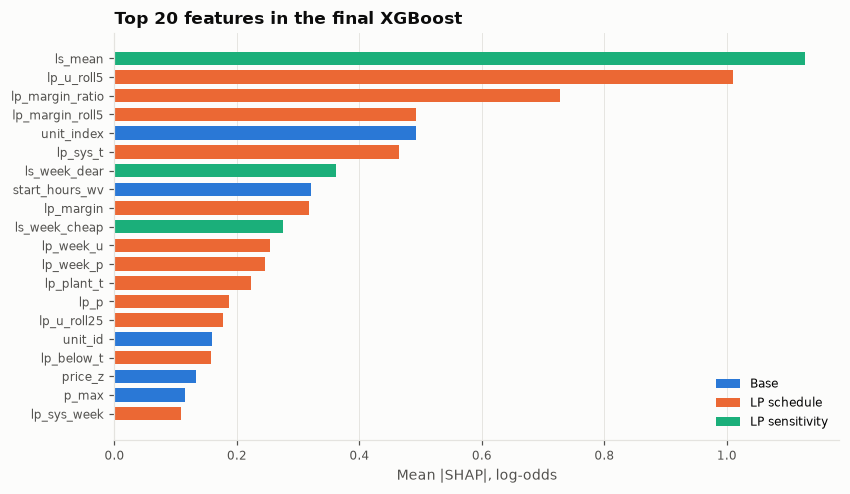

Share of total mean |SHAP| by group: {'base': 0.221, 'lp': 0.577, 'ls': 0.202}
Top 8 by gain: ['lp_u_roll5', 'lp_u', 'ls_mean', 'lp_u_prev1', 'lp_u_next1', 'lp_u_roll13', 'lp_week_u', 'lp_week_p']


In [14]:
S = np.load("artifacts/shap_final.npz", allow_pickle=True)
sj = json.load(open("artifacts/shap_final.json"))
nm = S["names"]
imp = S["imp"]
o = np.argsort(-imp)[:20][::-1]
gc = {"base": BLUE, "lp": ORANGE, "ls": AQUA}
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(range(20), imp[o], color=[gc[group(nm[k])] for k in o], height=.72)
ax.set_yticks(range(20), nm[o])
ax.set_xlabel("Mean |SHAP|, log-odds")
ax.grid(axis="y", visible=False)
ax.set_title("Top 20 features in the final XGBoost")
for lab, gg in (("Base", "base"), ("LP schedule", "lp"), ("LP sensitivity", "ls")):
    ax.barh([0], [0], color=gc[gg], label=lab)
ax.legend(loc="lower right")
plt.show()
print("Share of total mean |SHAP| by group:", {k: round(v, 3) for k, v in sj["groups"].items()})
g_ = sj["gain"]
print("Top 8 by gain:", sorted(g_, key=g_.get, reverse=True)[:8])

LP features hold 78 % of the total attribution (LP schedule 58 %, LP sensitivity 20 %). The model builds on the LP's plan, as intended.

- **`ls_mean` ranks first, followed by `lp_u_roll5`.** `ls_mean` is the average of the three LP plans, so it says both what the LP decided and how firm the decision was: 1 means on in all three plans, and 1/3 or 2/3 means a near-tie. `lp_u_roll5` is the LP's on/off value averaged over five hours, which also tells the model whether a switch is close.
- **`lp_margin_ratio` and `lp_margin_roll5`** compare the price with the LP's marginal cost. They let the model refine the decision near the tipping point instead of copying the LP's plan.
- **`lp_sys_t`** describes the state of the whole system. **`unit_index`** (the unit's place in the start order) and the other unit columns capture how often each unit runs and in which order identical units start.
- **`start_hours_wv` surprised me.** It is the start cost measured in hours of full production valued at the water value. I expected a high value to discourage starting, but the next figure shows the opposite. High values occur when the water value is close to zero, so the feature seems to mark cheap water rather than expensive starts.

XGBoost's built-in importance (gain) ranks `lp_u_roll5` and `lp_u` first instead, because a few early splits with large gain use them. SHAP measures the effect on every prediction, so I rely on SHAP.

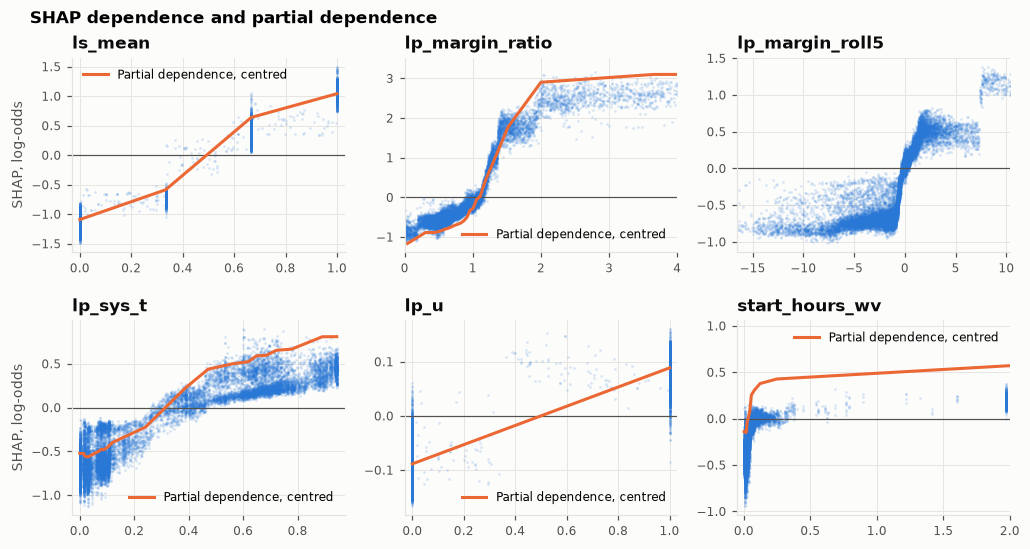

In [15]:
top = [str(x) for x in nm[S["top"]]]
show = ["ls_mean", "lp_margin_ratio", "lp_margin_roll5", "lp_sys_t", "lp_u", "start_hours_wv"]
fig, axs = plt.subplots(2, 3, figsize=(11, 5.4), gridspec_kw=dict(hspace=.35, wspace=.22))
for ax, n in zip(axs.ravel(), show):
    j = top.index(n)
    x, s = S["x"][:, j], S["sv"][:, j]
    hi = np.quantile(x, .995)
    lo = np.quantile(x, .005)
    ax.scatter(x, s, s=3, alpha=.18, c=BLUE, linewidths=0)
    ax.set_xlim(*{"lp_margin_ratio": (0, 4), "start_hours_wv": (-.05, 2)}.get(n, (lo - (hi - lo) * .03, hi + (hi - lo) * .03)))
    ax.axhline(0, color=MUTED, lw=.8)
    ax.set_title(n)
    if n in interp["pdp"]:
        q = interp["pdp"][n]
        base_ = np.mean(q["y"])
        ax.plot(q["x"], np.array(q["y"]) - base_, color=ORANGE, label="Partial dependence, centred")
        ax.legend(loc="best")
axs[0, 0].set_ylabel("SHAP, log-odds")
axs[1, 0].set_ylabel("SHAP, log-odds")
fig.suptitle("SHAP dependence and partial dependence", fontsize=11, fontweight="bold", x=.09, ha="left", y=.96)
plt.show()

Each blue dot is one prediction: the feature's value (x axis) against how much it pushed that prediction, in log-odds (y axis). The orange line is partial dependence, centred at zero.

- `ls_mean` takes the values 0, 1/3, 2/3 and 1. Each step raises the odds of running, most of all from 1/3 to 2/3, where the majority of the three LP plans switches from off to on.
- `lp_margin_ratio` and `lp_margin_roll5` rise steeply where the price passes the LP's marginal cost (ratio 1, margin 0). The model is most sensitive exactly at the LP's tipping point.
- `lp_sys_t` rises with total system output. `lp_u` itself has small effects (about ±0.1), since `lp_u_roll5` and `ls_mean` carry the same information.
- Partial dependence (computed on 20 000 rows) agrees with SHAP in direction. The sizes differ because partial dependence sets one feature to each value for all rows, which creates combinations that never occur in the data.

### 8.2 Per-unit attribution

Does the model rely on the same features for every unit?

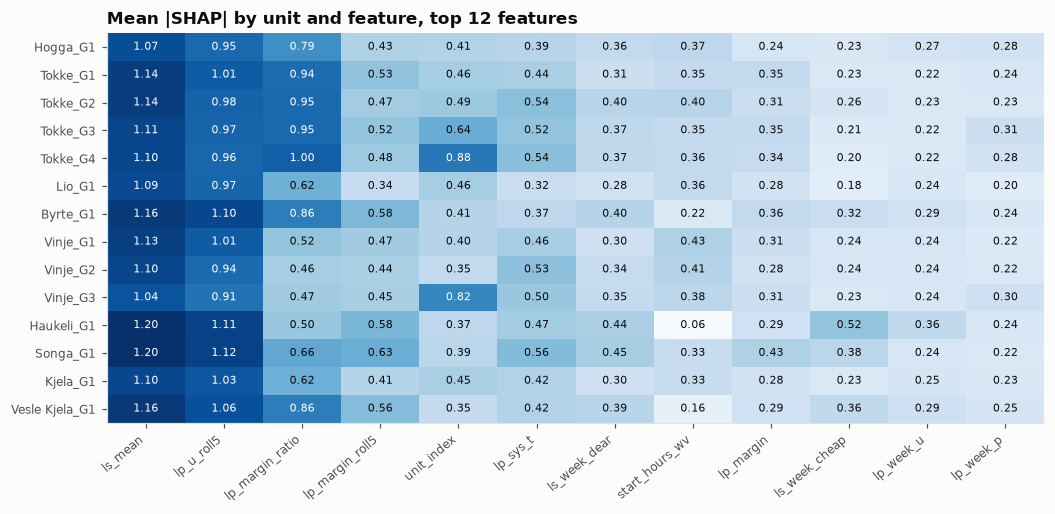

In [16]:
un = S["unit"]
ks = [top.index(n) for n in top[:12]]
M = np.array([[np.abs(S["sv"][un == g_, k]).mean() for k in ks] for g_ in range(14)])
fig, ax = plt.subplots(figsize=(11, 4.6))
heat(ax, M, [top[k] for k in ks], UNITS, "Mean |SHAP| by unit and feature, top 12 features", fmt="{:.2f}")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

Mostly yes. `ls_mean` is the most important feature for every unit. `unit_index` matters most for units late in the start order (Tokke G4 0.88, Vinje G3 0.82), which only run when the units ahead of them are already on. `start_hours_wv` matters least for Haukeli (0.06), which rarely switches (0.5 switches per week, Section 3.4).

### 8.3 Permutation importance: trees, net and blend

Permutation importance works for both models and for the blend. For each (case, unit), the week-long values of a feature are replaced by the values from another random (case, unit), and the drop in AUC is measured. A large drop means the model depends on the feature. The shuffled inputs are not physically consistent, for example a price from another week, so the drop measures sensitivity rather than a clean importance. Feature groups are shuffled 3 times, single features once.

Hypothesis, written in the log before the run: both models rely mainly on the LP schedule, and the network loses more than the trees when market columns are shuffled, because only the network sees absolute price levels.

Unshuffled AUC on 2022, seed 0: {'xgb': 0.99283, 'net': 0.99151, 'blend': 0.99315}


,xgb,net,blend,columns
Shuffled group,,,,
lp_schedule,-0.24641,-0.28287,-0.23613,36
lp_sensitivity,-0.01294,-0.00730,-0.00812,7
unit,-0.00460,-0.09149,-0.00360,5
market,-0.00054,-0.00765,-0.00151,10
calendar,-0.00130,-0.00066,-0.00109,5
water_state,-0.00084,-0.00202,-0.00087,9


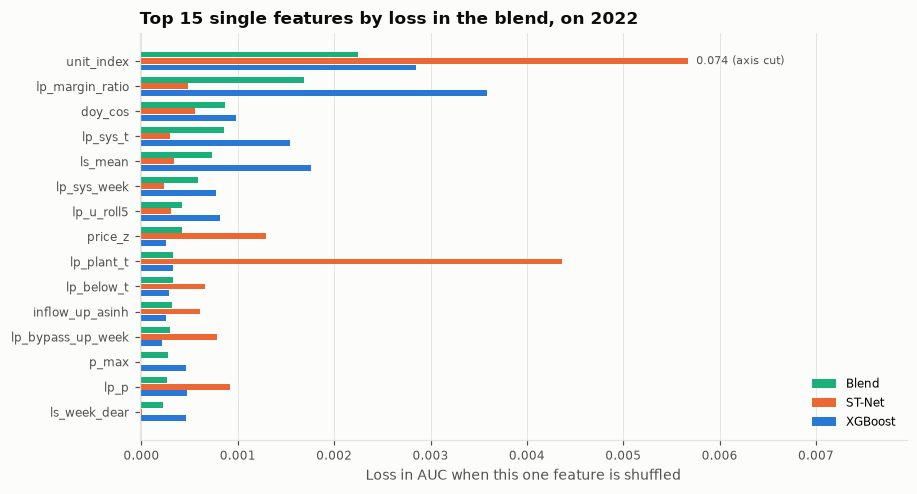

In [17]:
gi = pd.DataFrame(interp["group"]).T[["xgb", "net", "blend"]]
gi["columns"] = [len(G[k]) for k in gi.index]
print("Unshuffled AUC on 2022, seed 0:", {k: round(v, 5) for k, v in interp["base"].items()})
display(gi.sort_values("blend").round(5).rename_axis("Shuffled group"))
si = pd.DataFrame(interp["single"]).T
si = si.sort_values("blend").head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(si))
w_ = .26
loss = -si[["xgb", "net", "blend"]]
cut = float(np.sort(loss.values.ravel())[-2]) * 1.3  # the axis is cut above the second largest loss
for k, (m_, col) in enumerate((("xgb", BLUE), ("net", ORANGE), ("blend", AQUA))):
    ax.barh(yy + (k - 1) * w_, np.minimum(loss[m_], cut), height=w_ * .9, color=col, label={"xgb": "XGBoost", "net": "ST-Net", "blend": "Blend"}[m_])
    for j in np.where(loss[m_].values > cut)[0]:
        ax.text(cut, yy[j] + (k - 1) * w_, f"  {loss[m_].values[j]:.3f} (axis cut)", va="center", fontsize=7.5, color=MUTED)
ax.set_xlim(min(0., float(loss.values.min()) * 1.2), cut * 1.4)
ax.set_yticks(yy, si.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Loss in AUC when this one feature is shuffled")
ax.set_title("Top 15 single features by loss in the blend, on 2022")
hl, lb = ax.get_legend_handles_labels()
ax.legend(hl[::-1], lb[::-1], loc="lower right")
plt.show()

The hypothesis held. Shuffling the LP schedule costs 0.25 AUC in the trees and 0.28 in the network, far more than any other group, and LP sensitivity follows with about 0.01. Shuffling the market columns costs the network 0.0077 but the trees only 0.0005.

One result was not predicted: the network loses 0.091 when the unit group is shuffled, and 0.074 from `unit_index` alone, although it also has a learned embedding for each unit. A possible reason, not tested: `unit_index` never varies apart from the unit embedding in training, so shuffling creates combinations the network has never seen, and the drop measures extrapolation more than reliance. The blend loses only 0.0022 on that column.

Single features cost at most about 0.002 in the blend, because LP columns can stand in for each other. The group table is therefore the better guide. Single features use one shuffle and one seed, so differences below about 0.0002 are not meaningful. In the figure the axis is cut so the small bars stay readable, and the network's bar for `unit_index` carries its value.

### 8.4 Two weeks, side by side

Numbers alone hide what the predictions look like. The figures show two weeks, each predicted by a model that did not see that year in training: a typical week, the case with the median blend AUC, and a hard week, the case at the 10th percentile (one week in ten is harder). From the top: the price and the water value above Tokke; SHOP's decisions (dark means on); the LP's plan, with no training; and the blend's predicted probability of running.

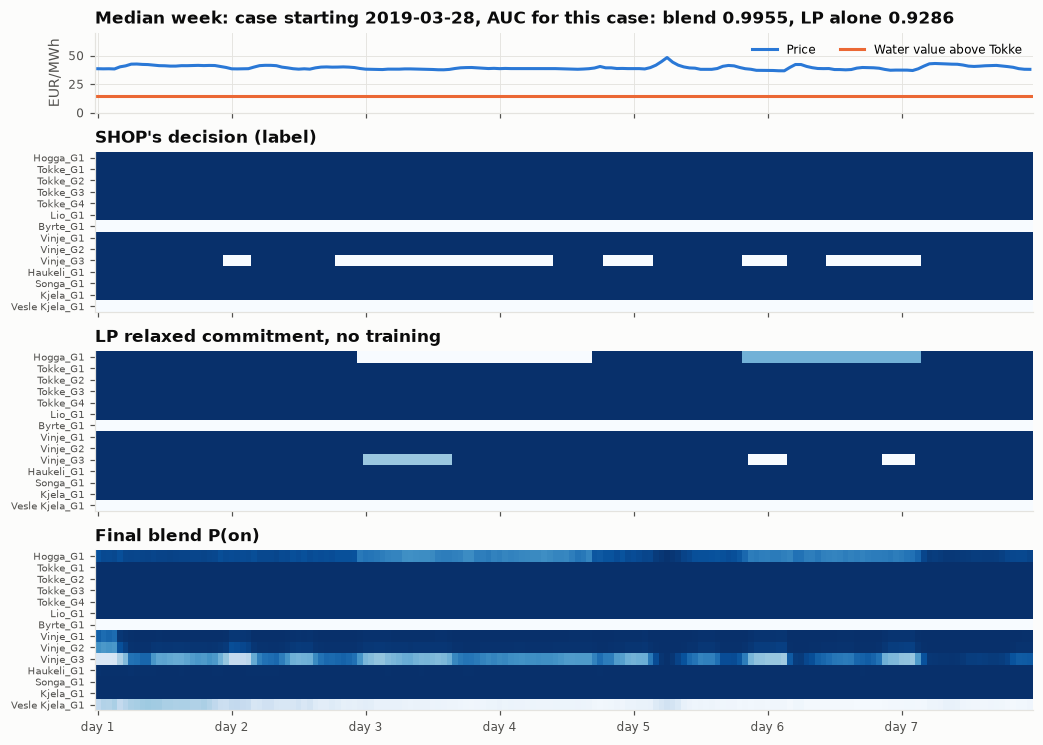

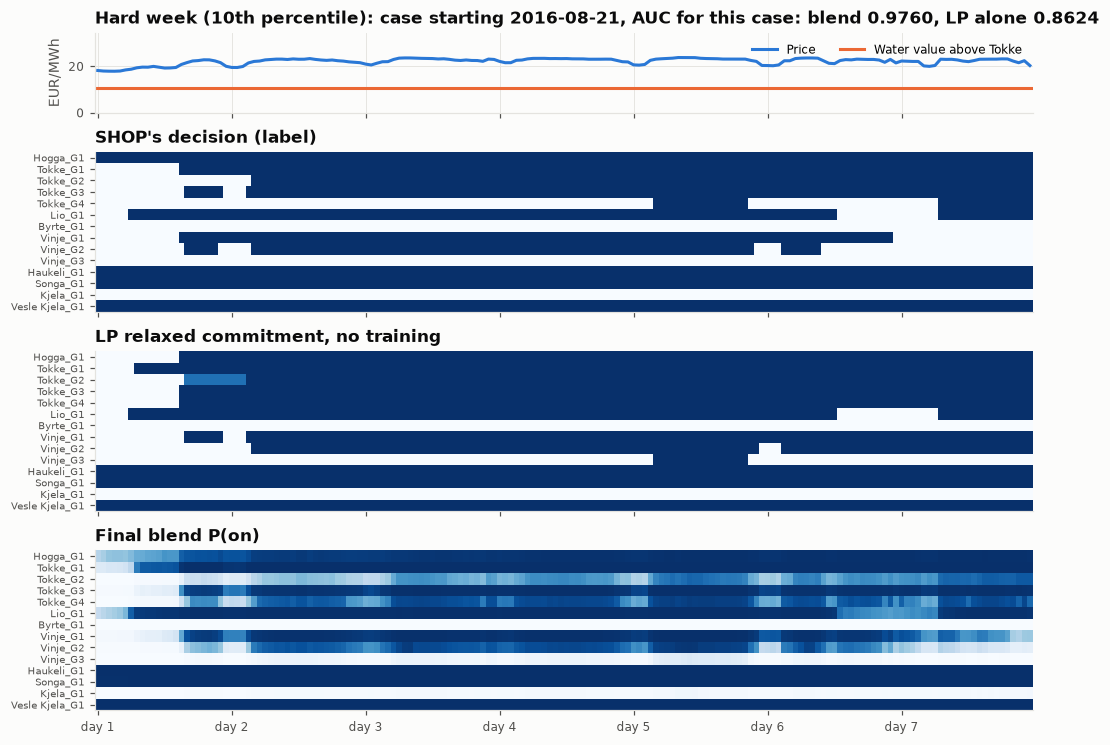

In [18]:
ca = np.array([auc(Y[k].ravel(), B[k].ravel()) if 0 < Y[k].mean() < 1 else np.nan for k in range(N_TR)])
def show_week(k, name):
    fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True, gridspec_kw=dict(hspace=.28, height_ratios=[1, 2, 2, 2]))
    axs[0].plot(P[k], color=BLUE, label="Price")
    wvu = wv[k, ri[UP[UNITS.index("Tokke_G1")]]]
    axs[0].axhline(wvu, color=ORANGE, label="Water value above Tokke")
    axs[0].set_ylabel("EUR/MWh")
    axs[0].set_ylim(0, max(P[k].max(), wvu) * 1.45)
    axs[0].legend(loc="upper right", ncol=2)
    axs[0].set_title(f"{name}: case starting {c['start'][k]}, AUC for this case: blend {ca[k]:.4f}, LP alone {auc(Y[k].ravel(), LPU[k].ravel()):.4f}")
    for ax, M, tt in ((axs[1], Y[k], "SHOP's decision (label)"), (axs[2], LPU[k], "LP relaxed commitment, no training"), (axs[3], 1 / (1 + np.exp(-B[k])), "Final blend P(on)")):
        ax.imshow(M, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
        ax.grid(False)
        ax.set_yticks(range(14), UNITS, fontsize=6.5)
        ax.set_title(tt)
    axs[3].set_xticks(range(0, 168, 24), [f"day {d + 1}" for d in range(7)])
    plt.show()
show_week(int(np.nanargmin(np.abs(ca - np.nanmedian(ca)))), "Median week")
show_week(int(np.nanargmin(np.abs(ca - np.nanquantile(ca, .1)))), "Hard week (10th percentile)")

In the median week SHOP runs every unit except Byrte and Vesle Kjela all week, and only Vinje G3 switches. The LP gets twelve of the fourteen units right without any training. Its errors are Hogga, which it switches off on days 3-5 and partly off on days 6-7 while SHOP keeps it running, and Vinje G3, which SHOP switches off five times but the LP only two short times. The blend keeps Hogga likely on, with less certainty where the LP has it off, and gives Vinje G3 a lower probability in the hours SHOP has it off, without placing the switches exactly. This matches the interpretation above: the models build on the LP's plan and adjust it, rather than replacing it.

The hard week shows where the LP goes wrong and how far the models get. The price stays above the water value above Tokke all week, so from the second day the LP runs all four Tokke units and the first two Vinje units for nearly the rest of the week. SHOP is more selective. It runs Tokke G4 for only 34 of 168 hours, against 153 for the LP, and it stops Vinje G1 and G2 towards the end of the week, which the LP keeps on. The blend corrects part of this. Vinje G3, which the LP runs for 17 hours and SHOP not at all, gets a probability of about 0.1 in those hours. For Tokke G4 the blend ranks SHOP's running hours above the others (mean probability 0.91 against 0.66), but still predicts most of the idle hours as likely on. The case's AUC rises from 0.86 for the LP alone to 0.976. The largest remaining error is Tokke G4's weekly level, which fits the finding in Section 9 that part of the error lies in the weekly level.

## 9. Error analysis

Where does the final blend still go wrong? All results use out-of-fold LOYO predictions for 2015-2022, so each case is predicted by a model that did not see its year.

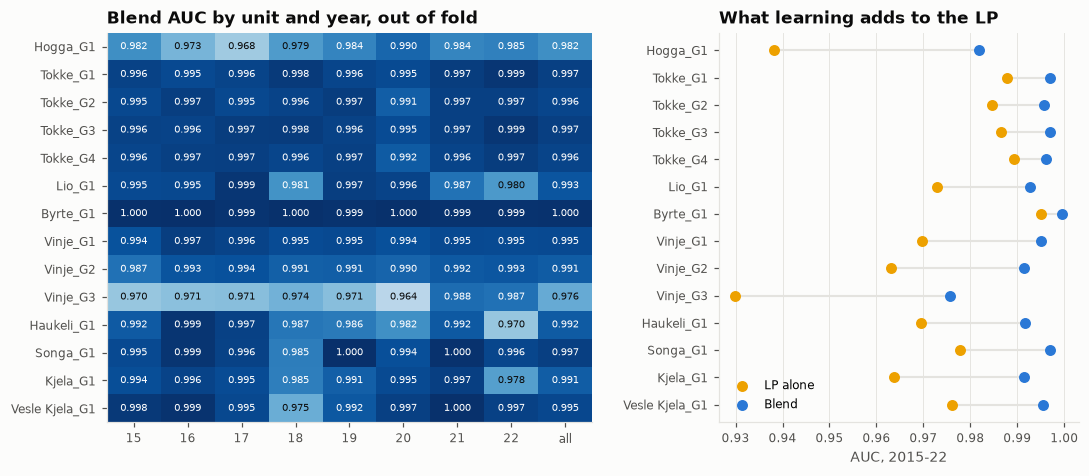

,Vinje_G3,Hogga_G1,Kjela_G1,Vinje_G2,Haukeli_G1,Lio_G1,Vinje_G1,Vesle Kjela_G1,Tokke_G2,Tokke_G4,Tokke_G1,Tokke_G3,Songa_G1,Byrte_G1
LP alone,0.9299,0.9381,0.9638,0.9631,0.9696,0.9729,0.9696,0.9761,0.9845,0.9892,0.9877,0.9865,0.9779,0.9950
XGBoost,0.9741,0.9804,0.9906,0.9906,0.9914,0.9919,0.9946,0.9953,0.9953,0.9957,0.9966,0.9966,0.9967,0.9995
ST-Net,0.9735,0.9806,0.9911,0.9914,0.9903,0.9923,0.9948,0.9948,0.9955,0.9958,0.9967,0.9969,0.9966,0.9995
Blend,0.9757,0.9818,0.9914,0.9915,0.9917,0.9928,0.9951,0.9955,0.9958,0.9960,0.9969,0.9969,0.9970,0.9996


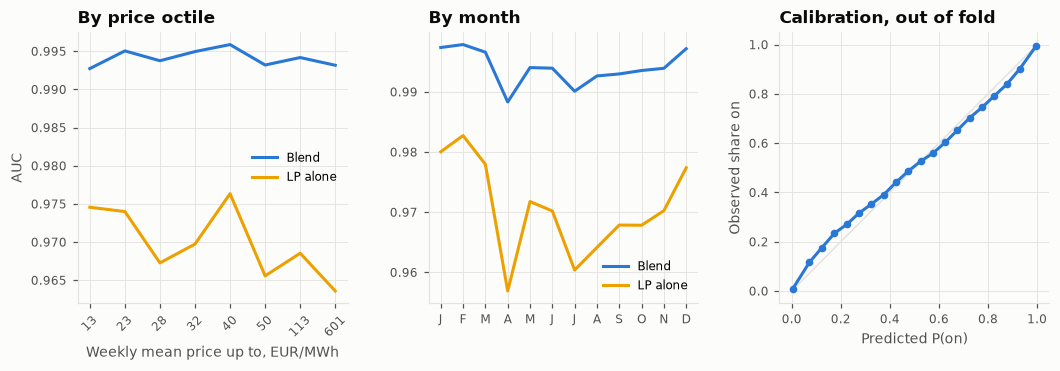

Blend AUC per year: {2015: 0.99454, 2016: 0.99587, 2017: 0.99507, 2018: 0.99075, 2019: 0.99474, 2020: 0.99267, 2021: 0.99578, 2022: 0.99313}


AUC if only the weekly level were known, true level: 0.9809 | blend's level: 0.9734


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.6), gridspec_kw=dict(wspace=.3, width_ratios=[1.35, 1]))
M = np.array([[auc(Y[ytr == y, g_], B[ytr == y, g_]) for y in YRS] + [auc(Y[:, g_], B[:, g_])] for g_ in range(14)])
heat(ax[0], M, [str(y)[2:] for y in YRS] + ["all"], UNITS, "Blend AUC by unit and year, out of fold", .95, 1., "{:.3f}", cmap="Blues", size=6.5)
L = [auc(Y[:, g_], LPF[:N_TR, g_]) for g_ in range(14)]
Bl = [auc(Y[:, g_], B[:, g_]) for g_ in range(14)]
X_ = [auc(Y[:, g_], XT[:, g_]) for g_ in range(14)]
N_ = [auc(Y[:, g_], NT[:, g_]) for g_ in range(14)]
yy = np.arange(14)
ax[1].hlines(yy, L, Bl, color=GRID, lw=1.4)
ax[1].scatter(L, yy, s=38, c=YELLOW, label="LP alone", zorder=3)
ax[1].scatter(Bl, yy, s=38, c=BLUE, label="Blend", zorder=3)
ax[1].set_yticks(yy, UNITS)
ax[1].invert_yaxis()
ax[1].grid(axis="y", visible=False)
ax[1].legend(loc="lower left")
ax[1].set_title("What learning adds to the LP")
ax[1].set_xlabel("AUC, 2015-22")
plt.show()
display(pd.DataFrame({"LP alone": L, "XGBoost": X_, "ST-Net": N_, "Blend": Bl}, index=UNITS).round(4).sort_values("Blend").T)
wm = P[:N_TR].mean(1)
bins = np.quantile(wm, np.linspace(0, 1, 9))
pb = np.digitize(wm, bins[1:-1])
mo = starts[:N_TR].month.values
ex = lambda a, m: auc(Y[m], a[m])
fig, ax = plt.subplots(1, 3, figsize=(11.4, 3.2), gridspec_kw=dict(wspace=.3))
ax[0].plot(range(8), [ex(B, pb == k) for k in range(8)], color=BLUE, label="Blend")
ax[0].plot(range(8), [ex(LPF[:N_TR], pb == k) for k in range(8)], color=YELLOW, label="LP alone")
ax[0].set_xticks(range(8), [f"{bins[k + 1]:.0f}" for k in range(8)], rotation=45)
ax[0].set_xlabel("Weekly mean price up to, EUR/MWh")
ax[0].set_ylabel("AUC")
ax[0].set_title("By price octile")
ax[0].legend()
ax[1].plot(range(1, 13), [ex(B, mo == m) for m in range(1, 13)], color=BLUE, label="Blend")
ax[1].plot(range(1, 13), [ex(LPF[:N_TR], mo == m) for m in range(1, 13)], color=YELLOW, label="LP alone")
ax[1].set_xticks(range(1, 13), ml)
ax[1].set_title("By month")
ax[1].legend()
pb_ = 1 / (1 + np.exp(-B))
bn = np.linspace(0, 1, 21)
ix = np.digitize(pb_.ravel(), bn) - 1
mp = [pb_.ravel()[ix == k].mean() for k in range(20)]
my = [Y.ravel()[ix == k].mean() for k in range(20)]
ax[2].plot([0, 1], [0, 1], color=GRID, lw=1)
ax[2].plot(mp, my, color=BLUE, marker="o", ms=4)
ax[2].set_xlabel("Predicted P(on)")
ax[2].set_ylabel("Observed share on")
ax[2].set_title("Calibration, out of fold")
plt.show()
print("Blend AUC per year:", {y: round(auc(Y[ytr == y], B[ytr == y]), 5) for y in YRS})
lv = lambda A: np.broadcast_to(A.mean(2, keepdims=True), A.shape)
print("AUC if only the weekly level were known, true level:", round(auc(Y, lv(Y)), 4), "| blend's level:", round(auc(Y, lv(B)), 4))

- **Units.** Learning adds most where the LP is weakest: Vinje G3 rises from 0.930 to 0.976, Hogga from 0.938 to 0.982 and Kjela from 0.964 to 0.991. These are still the three weakest units. Byrte (0.9996) and the Tokke units (about 0.996) are nearly solved. The blend matches or beats both of its members on 13 of 14 units, even though their log-odds correlate at 0.97; on Tokke G3 it is 0.00001 below the network.
- **Unit and year.** The weakest cells are Vinje G3 2020 (0.964), Hogga 2017 (0.968), Vinje G3 2015 (0.970), Haukeli 2022 (0.970) and Vinje G3 2016 (0.971). Vinje G3 is below 0.975 in six of eight years. The weakest year overall is 2018 (0.991). 2020, by far the hardest year in Phase 1 (0.977 for E021a), is now at 0.993.
- **Price and month.** Performance is nearly flat across price levels (0.993-0.996). This matters, because the test years have different price levels. April is the weakest month for both the blend and the LP (0.988 and 0.958), followed by July. I did not investigate why.
- **Weekly level.** Knowing only each unit's true share of hours on in the week would give AUC 0.981. The blend's own weekly level gives 0.973. Part of the remaining error is therefore in the weekly level, not only in the hour-by-hour timing.
- **Calibration.** Predicted probabilities are close to the observed frequencies, but slightly too confident at low probabilities (predicted about 0.07, observed 0.12; predicted 0.12, observed 0.18). AUC depends only on the ranking, so I did not recalibrate.

## 10. Robustness

The test years differ from the training years (Section 3.5) and contain negative prices. This section asks how well the models hold up when conditions change.

### 10.1 Regime holdouts

Here XGBoost is trained on one kind of period and tested on another, for example early against late years, or low-price against high-price weeks. Each holdout is run without the LP features, with them, and with them but without absolute prices; the last column is the LP alone. These runs used LP v4 and were not repeated on v5. One caveat: I designed the LP while seeing labels from all these years.

,n train,n val,No LP,LP with prices,"LP, no prices",LP alone (no training)
holdout,,,,,,
train_2015_18_test_2019_22,1461,1461,0.92693,0.99313,0.99281,0.97228
train_2015_19_test_2021_22,1826,730,0.92259,0.99343,0.99330,0.97257
train_2015_20_test_2022,2192,365,0.93113,0.99206,0.99190,0.96757
train_price_low_test_high,2057,742,0.93216,0.99159,0.99176,0.96912
train_price_high_test_low,612,2180,0.90986,0.98995,0.98960,0.97042
train_no_2020_like_test_2020,2424,366,0.92581,0.99069,0.98987,0.97197


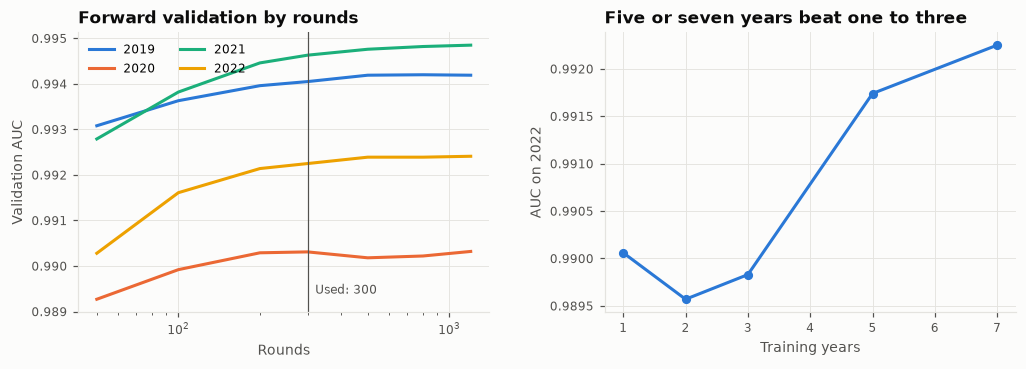

In [20]:
rr = pd.read_csv("artifacts/robust_regime.csv").set_index("holdout")
rr.columns = ["n train", "n val", "No LP", "LP with prices", "LP, no prices", "LP alone (no training)"]
display(rr)
rc = json.load(open("artifacts/robust_curves.json"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw=dict(wspace=.28))
rs = ["50", "100", "200", "300", "500", "800", "1200"]
for (y, d), col in zip(rc["rounds"].items(), (BLUE, ORANGE, AQUA, YELLOW)):
    ax[0].plot([int(r) for r in rs], [d[r][1] for r in rs], color=col, label=f"{y}")
ax[0].axvline(300, color=MUTED, lw=.8)
ax[0].text(320, ax[0].get_ylim()[0] + .0004, "Used: 300", fontsize=8, color=MUTED)
ax[0].set_xscale("log")
ax[0].set_xlabel("Rounds")
ax[0].set_ylabel("Validation AUC")
ax[0].set_title("Forward validation by rounds")
ax[0].legend(ncol=2)
sz = rc["size"]
ax[1].plot([int(k) for k in sz], list(sz.values()), color=BLUE, marker="o", ms=5)
ax[1].set_xlabel("Training years")
ax[1].set_ylabel("AUC on 2022")
ax[1].set_title("Five or seven years beat one to three")
plt.show()

- **The LP makes the models robust to new conditions.** Without LP features the holdouts score 0.91-0.93; with them about 0.99. This gap is larger than any difference between model types in Section 6, so for robustness the features matter more than the choice of model.
- **300 boosting rounds is not overfitting.** More rounds never lower validation by more than 0.0001 (2020: 0.99031 at 300 rounds, 0.99018 at 500). Going from 300 to 1200 rounds gains at most 0.0002, and R13 found more rounds to be within noise.
- **More years help.** Five or seven training years beat one to three (0.9917 and 0.9923 against about 0.990), so the final models train on all eight.

### 10.2 Stress tests

Here the inputs for half of 2022's cases are deliberately changed, **the LP is solved again** on the changed inputs, and models trained before 2022 make the predictions. The labels stay the same, but SHOP's real decision could change under the new inputs, so these numbers show sensitivity, not true scores. The changes are: scaling prices and water values together (as if the whole market's price level changed), adding noise to prices, and pushing the cheapest 10 % of hours below zero to imitate the negative prices in the test years.

In [21]:
sf, sn = json.load(open("artifacts/stress_final.json")), json.load(open("artifacts/stress_noabs.json"))
kk = ["scale_0.5", "scale_2", "scale_4", "price_noise", "negative_cheapest"]
display(pd.DataFrame({"XGBoost": [sf[k]["xgb"] for k in kk], "ST-Net, notebook 1": [sf[k]["net"] for k in kk], "ST-Net, notebook 2": [sn[k]["net"] for k in kk], "Blend, notebook 1": [sf[k]["blend"] for k in kk], "Blend, notebook 2": [sn[k]["blend"] for k in kk], "LP schedule changed": [sf[k]["lp_u_change"] for k in kk]}, index=["Price & water value x0.5", "Price & water value x2", "Price & water value x4", "Noise on price", "Cheapest 10 % of hours pushed below zero"]).round(5))
print("Unperturbed blend on this half of 2022: notebook 1", round(sf["base"]["blend"], 5), "| notebook 2", round(sn["base"]["blend"], 5))
print("Mean P(on) in the hours pushed negative: before", round(sf["negative_cheapest"]["p_on_before"], 3), "after", round(sf["negative_cheapest"]["p_on_after"], 3), "| LP:", round(sf["negative_cheapest"]["lp_on_before"], 3), "to", round(sf["negative_cheapest"]["lp_on_after"], 3))
s1 = pd.read_csv("artifacts/submission_1.csv")
T1 = s1.iloc[:, 1:].values.reshape(725, 14, 168)
P2 = P[N_TR:]
neg = np.broadcast_to(P2[:, None] < 0, T1.shape)
print("\nOn the actual test set (no labels). Mean P(on) in negative-price hours:", round(T1[neg].mean(), 3), "| all other hours:", round(T1[~neg].mean(), 3), "| LP power fraction in negative hours:", round(LPF[N_TR:][neg].mean(), 3))

,XGBoost,"ST-Net, notebook 1","ST-Net, notebook 2","Blend, notebook 1","Blend, notebook 2",LP schedule changed
Price & water value x0.5,-0.00023,-0.00017,-0.00042,-0.00022,-0.00031,0.00962
Price & water value x2,0.00066,-0.00031,0.00065,0.00043,0.00064,0.00832
Price & water value x4,-0.00266,-0.00528,-0.00310,-0.00287,-0.00260,0.01747
Noise on price,-0.00694,-0.00784,-0.00812,-0.00693,-0.00700,0.04605
Cheapest 10 % of hours pushed below zero,-0.00539,-0.00654,-0.00496,-0.00552,-0.00512,0.01661


Unperturbed blend on this half of 2022: notebook 1 0.99303 | notebook 2 0.99307
Mean P(on) in the hours pushed negative: before 0.137 after 0.011 | LP: 0.14 to 0.005



On the actual test set (no labels). Mean P(on) in negative-price hours: 0.142 | all other hours: 0.478 | LP power fraction in negative hours: 0.078


The table shows the change in AUC against the unperturbed inputs, and the share of the LP's decisions that changed.

- **Scaling** prices and water values together barely changes the result up to x2, because the LP's plan hardly changes (0.8-1.0 % of its decisions). At x4, 1.7 % of the LP's decisions change and the blend loses 0.003.
- **Negative prices are the largest unknown.** The blend loses 0.0055 AUC. The best model without the LP (E021a) lost 0.0229 under the same change, on different validation data, so the comparison is only indicative. In the hours pushed below zero, the predicted probability of running falls from 0.14 to 0.01. On the real test set, the mean predicted probability is 0.14 in negative-price hours and 0.48 in other hours. The direction is sensible, since producing at a negative price costs money, but how strongly SHOP reacts cannot be checked without labels.
- **Price noise** costs 0.0069, but it is the least relevant test, because SHOP and the features always see the same price.

**Why notebook 2 exists.** Notebook 1 bets that absolute price levels help the network, as they did on LP v4 (R6, R21). If the test years' price levels mislead it, that bet loses. Notebook 2 removes these columns from the network too, so no part of the model reads the price level directly. Under the stress tests it holds up somewhat better: the blend loses 0.0026 instead of 0.0029 when prices are scaled x4, and 0.0051 instead of 0.0055 with negative prices. It costs nothing in validation (LOYO 0.9943 for both, forward 0.99408 against 0.99404). Both notebooks share the LP, so this hedge does not protect against the LP itself failing. I considered a model without the LP (E026) as the hedge instead, but rejected it: its LOYO is about 0.012 lower, and its predecessor E013 lost 0.029 with negative prices (indicative).

The public leaderboard agrees that the hedge costs almost nothing: 0.99649 for notebook 2 against 0.99651 for notebook 1.

## 11. Reproducibility

The course requires that the short notebooks reproduce the selected predictions from the raw data, offline, within 12 hours on a normal PC (at most 4 CPU cores and 32 GB RAM). I tested this directly.

Both notebooks contain all their code, start from the raw data, run offline and use no external data. LP solutions are saved in `work/`, so an interrupted run can resume. XGBoost and ST-Net each fall back to the CPU if the GPU fails.

The submitted files were made without a GPU. The table gives times in minutes. Each run started from an empty directory, with 4 cores and a 32 GB memory limit enforced by Slurm.

| Run | Hardware | Total | LP | XGBoost | ST-Net | Peak RAM (GiB) | Against submitted file |
|---|---|---|---|---|---|---|---|
| Notebook 1 | No GPU, Xeon 6730P | 227 | 109 | 3.9 | 114 | 17.7 | Is the submitted file |
| Notebook 2 | No GPU, Xeon 6730P | 224 | 108 | 3.6 | 112 | 17.7 | Is the submitted file |
| Notebook 1, second run | No GPU, Xeon 6730P, another node | 206 | 107 | 4.9 | 94 | 17.7 | Byte-identical |
| Notebook 2, second run | No GPU, Xeon 6730P, same node | 224 | 116 | 3.9 | 104 | 17.7 | Byte-identical |

With the previous LP (v4), the same notebooks also ran on other hardware: 40 minutes on an H100 GPU, 166 minutes without a GPU on a Xeon Gold 6348, and 277-307 minutes on a node with a Tesla P100, all from an empty directory with the same limits.

- **The LP gives the same result everywhere.** Each LP solve has a time limit, and a limit that is reached would make the result depend on the computer's speed, so I checked this directly: a second run of all 3647 cases on a different machine (Xeon Gold 6132) gave bit-identical schedules, shadow prices and flows. The LP solutions from the notebooks' own copy of the code, saved in the two second runs above, are bit-identical to them too, for all three solves of every case. No case reached a limit: the slowest of Lio's integer steps took 2 minutes against a limit of 10.
- **Same hardware gives the same file.** Each notebook was run a second time on the same CPU model, notebook 1 on another node, and both gave a byte-identical submission file. Training on other hardware changes the predictions slightly: on LP v4, files from a GPU and from a CPU had rank correlation 0.999 with each other.
- **12 hours, 4 CPU cores, 32 GB.** Both notebooks meet the limits without a GPU: the slowest run took 3 h 47 min and used 17.7 GiB. The LP takes about half of the time; per solve it is 3.3-4.5 times slower than LP v4 on the same machine, mainly because of Lio's integer step.
- **GPU.** XGBoost 3.4.1 does not support the Tesla P100 (`not compiled for SM 60`) or the V100 (SM 70), so it falls back to the CPU there. On LP v4 I tested the ST-Net fallback by limiting GPU memory until training ran out of it.

Versions are in `requirements.txt`: Python 3.12, PyTorch 2.6.0 with CUDA 12.4, XGBoost 3.4.1, SciPy 1.18.1 with HiGHS.

## 12. Limitations

- **No untouched holdout.** I chose the LP's structure, for example telescoping water values, by scoring versions against labels from all training years. The same holds for the two corrections in LP v5, which I found by comparing the LP's plan with the labels unit by unit; the choice of Lio as the only unit with whole on/off decisions came from that comparison. The LOYO and forward scores for models with the LP are therefore somewhat optimistic. The public leaderboard is the only fully independent check, and I looked at it several times, which weakens it a little too. For LP v5 it is clean: the decision was fixed before the new files' public scores were known.
- **Negative prices** are 2.2 % of test hours (1.99 % in 2023, 2.35 % in 2024) but almost absent from training, so no model has learned how SHOP reacts to them. How these hours are split between the public and private test sets is unknown, so the private score may react differently from the public one.
- **Weakest units:** Vinje G3, Hogga and Kjela. Start costs and whole on/off decisions at small margins are a likely cause, but I did not establish this.
- **LP simplifications.** Head is fixed within a week, efficiency is concave, and on/off is relaxed to values between 0 and 1 for every unit except Lio. Vinje G3 is a known gap: in a quarter of the hours where the LP runs Vinje G3, SHOP runs only two Vinje units, and I could not find the cause. The models can only correct these simplifications where the training years show how.
- **Blend weight** not chosen nested for the final pair (Section 7).
- **Interpretation.** SHAP covers only the trees, shuffling breaks physical consistency, and correlated features share credit.
- **Runtime.** The slowest measured run of the final notebooks took 3 h 47 min, a factor of 3.2 below 12 hours. All runs used server CPUs, and a laptop can be slower. On Windows, which cannot fork processes, the notebooks solve the LP on one core instead of four. Scaled from the runs above, that is about 7 hours for the LP and 9-10 hours in total. This is an estimate; I did not test it.
- **Training hardware.** The submitted files and the comparison of LP v5 against v4 were trained on CPUs, since no GPU was available at the end of the project. CPU and GPU runs of the same models agree within 0.00002 in LOYO (Section 6.2), so this should not change the conclusions.

## 13. Conclusion

The central finding is that the labels are best predicted by first solving a simplified version of the problem that produced them. A linear program of the water system, with no trained parameters, reached an AUC of 0.97 on its own. Given its plan as features, the models went from 0.986 (the best without the LP) to 0.994 in cross-validation, and from 0.98906 to 0.99651 on the public leaderboard. Under changed conditions, models with the LP held at about 0.99, while models without it scored 0.91-0.93.

Three lessons stand out:

1. **Understanding how the data was generated paid off more than tuning.** Knowing that the labels came from an optimiser led to the LP. Hyperparameter tuning (E011) gave nothing measurable.
2. **Details of domain knowledge can matter enormously.** How the water values are read changed the LP's AUC from 0.743 to 0.932, and only testing against the labels revealed the right reading.
3. **Strict validation was necessary.** With scores above 0.99, most proposed changes were within noise. The gate, with each hypothesis written down before the run, kept me from accepting changes that only looked better.

The main open risk is the negative prices in the test years, which no training year shows. The models react in a sensible direction, and notebook 2 reduces the dependence on absolute price levels, but how SHOP itself reacts will only show on the private leaderboard.

**Tools:** Claude Code (an AI coding assistant) was used for code, analyses and drafting this report. Numbers come from logged runs.

## Appendix: experiment numbers

The text refers to runs in my experiment log by number. E numbers (Phase 1) are explained in the table in Section 6.1, and L, C, N, X and P runs (Phase 2) in the table in Section 6.2. The R numbers below are the hypotheses from the last rounds that the text cites. Each was written in the log before it ran. The full log, with every hypothesis and result, is `experiments/ledger.md` in the project repository: https://github.com/MartinNordli/Unit-Commitment-Problem/blob/main/experiments/ledger.md

| Number | What it tested | Result |
|---|---|---|
| R1 | Seed noise: XGBoost with 5 seeds | Standard deviation 0.00003 in LOYO, 0.00006-0.00009 forward. The gate's noise level was set to 0.0001 |
| R2 | Label control: labels shuffled between whole cases, on LP v4 | AUC 0.589, about what base rates give. No leakage visible |
| R3 | Drop the minimum-flow columns `mf_*` (trees) | LOYO -0.00001, forward -0.00007. Inside noise |
| R6 | Keep the absolute price columns | Trees: inside noise. Network: forward +0.0007 |
| R10 | ST-Net epochs (12, 16, 24), forward validation | 24 epochs best with absolute prices. Settled by R20 |
| R13 | XGBoost with learning rate 0.04 and 800 rounds | LOYO +0.00008, forward +0.00005. Inside noise, rejected |
| R14 | ST-Net with three other seeds | Three-seed ensembles differ by up to 0.00035. Six seeds add nothing in the blend |
| R15 | ST-Net with `d` = 96 | Forward 0.99132 against 0.99195, better in 1 of 4 years. Rejected |
| R16 | Blends of all model families, weights chosen nested in forward validation | XGBoost + network 0.99329; adding CatBoost 0.99334, below noise. Weights flat between 0.6 and 0.8 |
| R19 | Add `ls_*` to ST-Net, keeping `mf_*` and `lps_*` | LOYO +0.00006, 4 of 8 years. Fails the gate |
| R20 | 12 against 24 epochs on the same seeds | 24 epochs better on both seed sets, in LOYO and forward |
| R21 | ST-Net with `base,lp,ls` only | LOYO +0.00064 (7 of 8 years), forward +0.00083 (4 of 4). Accepted |